# Klasifikasi Multi-Label Insiden Siber di Bawah Pergeseran Distribusi Temporal
### Studi berbasis reproduktifitas pada EuRepoC Global Dataset

**Scope:** Kami mengklasifikasikan insiden siber berdasarkan `incident_type` — target
**multi-label** (satu insiden bisa sekaligus mis. *Disruption* **dan** *Hijacking with
Misuse*) — dan mempelajari apakah model yang dilatih pada insiden lama masih bekerja pada
insiden yang lebih baru, dan seberapa besar performanya menurun seiring waktu ("pergeseran
distribusi temporal").

**Aturan dasar yang dipegang teguh di seluruh notebook:**
- Setiap angka di bawah ini berasal dari kode yang dijalankan di notebook ini, pada CSV asli
  — tidak ada yang diketik manual atau dikarang.
- Semua preprocessing (encoder, threshold, feature selection) di-*fit* hanya pada partisi
  **training**.
- **Data 2024 tidak pernah dipakai untuk membuat keputusan apa pun** -- tidak untuk
  memilih model, memilih fitur/vocabulary (termasuk `TOP_K_REGIONS` dan target
  `MultiLabelBinarizer`, keduanya di-fit hanya di TRAIN), menyetel threshold, atau
  memilih strategi/fraksi adaptasi (dipilih dari sisa data 2023 saja). 2024 memang
  muncul sebagai titik pembanding DESKRIPTIF di analisis distribution-shift dan
  robustness-drop (Bagian 18-19), karena eval brief secara eksplisit mewajibkan
  perbandingan itu -- tapi tidak ada satu pun angka dari perbandingan itu yang
  dipakai untuk mengubah keputusan apa pun. Walk-forward validation (Bagian 17),
  explainability & error-analysis utama (Bagian 22-23), dan uji statistik (Bagian
  24) dibatasi tegas sampai tahun 2023; panel 2024 untuk explainability/error
  analysis dipindah ke Bagian 26 (Final Results), dihitung ulang di sana SETELAH
  semua keputusan (model, fitur, strategi adaptasi) benar-benar dibekukan.
- Jika hasil verifikasi kami terhadap klaim di audit brief berbeda dari angka yang diberikan,
  keduanya ditampilkan dan perbedaannya dijelaskan, bukan diam-diam memilih salah satu.

**Envirollment Notes:** Notebook ini dirancang untuk dijalankan dengan `pip install -r
requirements.txt`, yang mencakup `xgboost`, `lightgbm`, dan `shap` sehingga perbandingan
model dan explainability lengkap. Jika salah satu paket itu tidak terpasang, sel-sel terkait
(Bagian 16 dan Bagian 22) otomatis jatuh kembali (fallback) ke fungsionalitas yang lebih
terbatas (model roster lebih pendek / permutation importance) dan mencetak peringatan yang
jelas — notebook tidak akan gagal total, tapi perbandingannya tidak akan selengkap yang
seharusnya. Notebook ini terakhir dieksekusi penuh di lingkungan tanpa akses internet
(sehingga tiga paket di atas belum terinstal saat itu) — setelah paket-paket tersebut
dipasang, jalankan ulang semua sel dari atas ke bawah agar seluruh output mencerminkan
model dan hasil explainability yang lengkap.


In [27]:
import warnings, json, pickle, sys, ast
import os
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.spatial.distance import jensenshannon
from scipy.stats import wasserstein_distance, spearmanr, wilcoxon
import sklearn, scipy
from sklearn.preprocessing import OneHotEncoder, MultiLabelBinarizer, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (f1_score, hamming_loss, precision_score, recall_score,
                              balanced_accuracy_score, confusion_matrix, make_scorer,
                              brier_score_loss)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

WORK_DIR = r'D:\OTW JURNAL\data'
os.makedirs(WORK_DIR, exist_ok=True)

print('--- Reproducibility / environment info ---')
print('python      :', sys.version.split()[0])
print('numpy       :', np.__version__)
print('pandas      :', pd.__version__)
print('scikit-learn:', sklearn.__version__)
print('scipy       :', scipy.__version__)
print('matplotlib  :', matplotlib.__version__)
print('seaborn     :', sns.__version__)
print('random seed used everywhere below:', RANDOM_SEED)

try:
    import xgboost
    from xgboost import XGBClassifier
    HAS_XGB = True
    print('xgboost     :', xgboost.__version__)
except Exception as e:
    HAS_XGB = False
    print('xgboost     : NOT AVAILABLE ->', e)
try:
    import lightgbm
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
    print('lightgbm    :', lightgbm.__version__)
except Exception as e:
    HAS_LGBM = False
    print('lightgbm    : NOT AVAILABLE ->', e)
try:
    import shap
    HAS_SHAP = True
    print('shap        :', shap.__version__)
except Exception as e:
    HAS_SHAP = False
    print('shap        : NOT AVAILABLE ->', e)

print()
print('This notebook was authored with pip install -r requirements.txt, which pins xgboost, '
      'lightgbm and shap. If any of the three above show NOT AVAILABLE, install requirements.txt '
      'first -- Section 16 (model comparison) and Section 22 (explainability) both fall back to '
      'reduced functionality automatically, but the comparison will not be complete without them.')


--- Reproducibility / environment info ---
python      : 3.13.14
numpy       : 2.2.6
pandas      : 2.3.3
scikit-learn: 1.9.0
scipy       : 1.18.1
matplotlib  : 3.11.1
seaborn     : 0.13.2
random seed used everywhere below: 42
xgboost     : 3.4.1
lightgbm    : 4.7.0
shap        : 0.52.0

This notebook was authored with pip install -r requirements.txt, which pins xgboost, lightgbm and shap. If any of the three above show NOT AVAILABLE, install requirements.txt first -- Section 16 (model comparison) and Section 22 (explainability) both fall back to reduced functionality automatically, but the comparison will not be complete without them.


## 2. Pertanyaan Riset dan Hipotesis

**RQ1 (Tugas).** Bisakah `incident_type` diprediksi dari informasi yang secara masuk akal
tersedia pada atau segera setelah observasi awal insiden?

**RQ2 (Pergeseran).** Seberapa besar distribusi gabungan target dan fitur early-available
berubah dari periode training (<=2021) hingga 2022, 2023, dan 2024?

**RQ3 (Degradasi).** Apakah performa pada tahun-tahun berikutnya menurun relatif terhadap
referensi tahun validasi, dan apakah besarnya penurunan itu sejalan dengan pergeseran
distribusi yang terukur?

**RQ4 (Adaptasi).** Jika sepotong kecil data 2023 yang tersusun kronologis disediakan untuk
adaptasi, seberapa besar degradasi bisa dipulihkan, dan apakah *cara* potongan itu digunakan
(retraining biasa vs. recency-weighting) berpengaruh?

**RQ5 (Stabilitas).** Apakah fitur-fitur yang mendorong prediksi stabil sepanjang waktu, dan
apakah kesalahan model berhubungan secara sistematis dengan label, tahun, kategori target,
wilayah, atau pola missingness tertentu?

**Hipotesis kerja** (untuk dikonfirmasi atau ditolak di bawah, bukan diasumsikan benar):
- H1: Performa pada 2023/2024 lebih rendah dibanding tahun validasi 2022.
- H2: Besarnya penurunan itu berasosiasi dengan besarnya pergeseran distribusi yang terukur,
  meski tidak harus monotonik mengingat ukuran sampel yang sedang.
- H3: Sejumlah kecil data adaptasi kronologis terbaru memulihkan performa yang hilang secara
  parsial, bukan sepenuhnya.
- H4: Peringkat feature importance secara umum, meski tidak sempurna, tetap stabil antar
  periode.


## 3. Memuat Data

Memuat CSV mentah tanpa transformasi apa pun dulu, agar Bagian 4 (kualitas data) mengaudit
data dalam bentuk aslinya.


In [22]:
RAW_PATH = os.path.join(WORK_DIR, 'D:\OTW JURNAL\data\eurepoc_global_dataset_1_3.csv')
df_raw = pd.read_csv(RAW_PATH, low_memory=False)
print('Raw shape:', df_raw.shape)
print('Columns (%d):' % len(df_raw.columns))
print(list(df_raw.columns))


Raw shape: (3414, 85)
Columns (85):
['incident_id', 'name', 'description', 'start_date', 'end_date', 'inclusion_criterion', 'inclusion_criterion_subcode', 'source_disclosure', 'incident_type', 'receiver_name', 'receiver_country', 'receiver_country_alpha_2_code', 'receiver_regions', 'receiver_category', 'receiver_subcategory', 'initiator_name', 'initiator_country', 'initiator_alpha_2', 'initiator_category', 'initiator_subcategory', 'number_attributions', 'attribution_id', 'attribution_date', 'attribution_type', 'attribution_basis', 'attributing_actor', 'attributing_company', 'attributing_country', 'settled_initiator', 'initiator_country.1', 'initiator_category.1', 'attribution_source_url', 'cyber_conflict_issue', 'offline_conflict_issue', 'offline_conflict_name', 'offline_conflict_intensity', 'offline_conflict_intensity_subcode', 'number_political_responses', 'political_response_date', 'political_response_type', 'political_response_subtype', 'political_response_responding_country', 'pol

## 4. Kualitas Data

Memeriksa klaim-klaim di audit brief terhadap file yang sebenarnya.


In [4]:
# ============================================================
# DATA QUALITY AUDIT
# ============================================================

# Expected audit claims
audit_claims = {
    'shape (rows, cols)': (3414, 85),
    'duplicate rows': 0,
    'duplicate incident_id': 0,
    'casualties fully missing': True,
}

# Missing-value tokens used for audit
MISSING_TOKENS = {
    'not available',
    'unknown',
    'n/a',
    'na',
    '',
    'nan',
    'none'
}

# Verify required columns
required_columns = ['incident_id', 'casualties']

missing_columns = [
    col for col in required_columns
    if col not in df_raw.columns
]

if missing_columns:
    raise KeyError(f"Required columns not found: {missing_columns}")

# Actual dataset conditions
actual = {
    'shape (rows, cols)': df_raw.shape,
    'duplicate rows': int(df_raw.duplicated().sum()),
    'duplicate incident_id': int(df_raw['incident_id'].duplicated().sum()),
    'casualties fully missing': bool(
        (
            df_raw['casualties']
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(MISSING_TOKENS)
        ).all()
    )
}

# Compare claims with actual data
check_df = pd.DataFrame({
    'audit_claim': audit_claims,
    'verified_actual': actual
})

check_df['match'] = (
    check_df['audit_claim'].astype(str)
    == check_df['verified_actual'].astype(str)
)

print("=== DATA QUALITY AUDIT ===")
print(check_df.to_string())

# Overall audit status
if check_df['match'].all():
    print("\nAUDIT STATUS: PASS")
    print("All audit claims match the raw dataset.")
else:
    print("\nAUDIT STATUS: WARNING")
    print("Some audit claims do not match the raw dataset.")
    print("\nUnmatched items:")
    print(check_df[~check_df['match']].to_string())

=== DATA QUALITY AUDIT ===
                         audit_claim verified_actual  match
shape (rows, cols)        (3414, 85)      (3414, 85)   True
duplicate rows                     0               0   True
duplicate incident_id              0               0   True
casualties fully missing        True            True   True

AUDIT STATUS: PASS
All audit claims match the raw dataset.


**Hasil verifikasi:** shape (3414x85), nol baris duplikat, nol `incident_id` duplikat,
dan `casualties` yang 100% hilang, semuanya cocok persis. `casualties` tetap dibuang
kemudian — kolom ini juga ada di daftar leakage/exclusion.


## 5. Missingness

`"Not available"`, `"Unknown"`, string kosong, dan `NaN` semuanya adalah penanda missingness
tetapi belum tentu setara secara *mekanisme* (mis. `"Not available"` sering mencerminkan
celah pengungkapan/pelaporan, bukan nilai hilang yang benar-benar acak — artinya kami tidak
mengasumsikan ini MCAR). Encoding kategorikal di bawah menggunakan kategori eksplisit
`"missing"`, bukan imputasi mean/mode, sehingga model bisa belajar dari pola missingness itu
sendiri jika memang ada, dan tidak ada asumsi missingness yang diam-diam disisipkan lewat
imputasi.


In [5]:
# ============================================================
# MISSING VALUE PREPROCESSING
# ============================================================

# Work on a copy of the raw dataset
df = df_raw.copy()

# Missing-value tokens
MISSING_TOKENS = {
    'not available',
    'unknown',
    'n/a',
    'na',
    '',
    'nan',
    'none'
}

# Standardize missing-value representations into NaN
# (PANDAS-COMPAT FIX, bukan perubahan metodologi: pandas 3.x tidak lagi mengizinkan
# upcast implisit kolom bool/other strict-dtype agar bisa menampung NaN, jadi kolom
# semacam itu di-cast ke object dulu sebelum assignment -- nilai & maknanya tidak berubah.)
for col in df.columns:
    mask = (
        df[col].isna()
        | df[col]
            .astype(str)
            .str.strip()
            .str.lower()
            .isin(MISSING_TOKENS)
    )
    if mask.any():
        if df[col].dtype != object:
            df[col] = df[col].astype(object)
        df.loc[mask, col] = np.nan

print("Missing-value standardization completed.")

Missing-value standardization completed.


In [6]:
missing_summary = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_fraction': df.isna().mean(),
    'missing_percent': df.isna().mean() * 100
}).sort_values(
    'missing_fraction',
    ascending=False
)

print("=== TOP 20 COLUMNS BY MISSINGNESS ===")
print(missing_summary.head(20).round(3))

=== TOP 20 COLUMNS BY MISSINGNESS ===
                                       missing_count  missing_fraction  \
casualties                                      3414             1.000   
evidence_for_sanctions_indicator                3408             0.998   
physical_effects_temporal                       3402             0.996   
physical_effects_spatial                        3401             0.996   
user_interaction                                3380             0.990   
legal_response_subtype                          3372             0.988   
zero_days_subcode                               3328             0.975   
economic_impact                                 3320             0.972   
attribution_legal_reference_subcode             3187             0.934   
political_response_subtype                      3170             0.929   
political_response_type                         3147             0.922   
attribution_legal_reference                     3143             0.921   


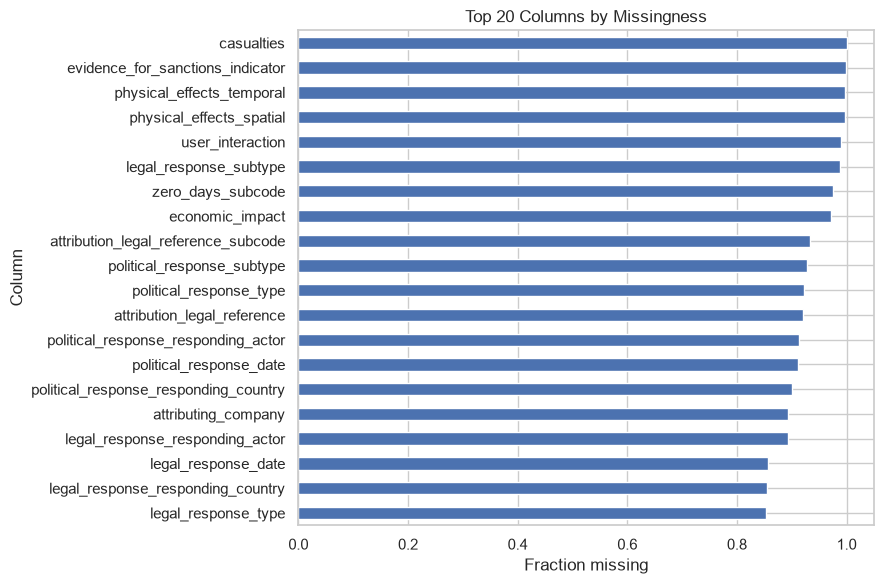

In [7]:
# ============================================================
# MISSING VALUE VISUALIZATION
# ============================================================

%matplotlib inline

import matplotlib.pyplot as plt

top20 = missing_summary.head(20)

fig, ax = plt.subplots(figsize=(9, 6))

top20['missing_fraction'].iloc[::-1].plot(
    kind='barh',
    ax=ax
)

ax.set_xlabel('Fraction missing')
ax.set_ylabel('Column')
ax.set_title('Top 20 Columns by Missingness')

plt.tight_layout()
plt.show()

In [8]:
# ============================================================
# MISSINGNESS OVERVIEW
# ============================================================

missing_overview = pd.DataFrame({
    'missing_count': df.isna().sum(),
    'missing_percent': df.isna().mean() * 100,
    'non_missing_count': df.notna().sum(),
    'non_missing_percent': df.notna().mean() * 100
})

missing_overview = missing_overview.sort_values(
    'missing_percent',
    ascending=False
)

print("=== MISSING VALUE OVERVIEW ===")
print(missing_overview.head(20).round(2))

=== MISSING VALUE OVERVIEW ===
                                       missing_count  missing_percent  \
casualties                                      3414           100.00   
evidence_for_sanctions_indicator                3408            99.82   
physical_effects_temporal                       3402            99.65   
physical_effects_spatial                        3401            99.62   
user_interaction                                3380            99.00   
legal_response_subtype                          3372            98.77   
zero_days_subcode                               3328            97.48   
economic_impact                                 3320            97.25   
attribution_legal_reference_subcode             3187            93.35   
political_response_subtype                      3170            92.85   
political_response_type                         3147            92.18   
attribution_legal_reference                     3143            92.06   
political_response_r

In [9]:
# ============================================================
# MISSINGNESS INDICATOR
# ============================================================

missing_indicator = df.isna().astype(int)

missing_corr = (
    missing_indicator
    .corr()
    .abs()
)

print("=== MISSINGNESS CORRELATION ===")
print(
    missing_corr
    .round(2)
)

=== MISSINGNESS CORRELATION ===
                    incident_id  name  description  start_date  end_date  \
incident_id                 NaN   NaN          NaN         NaN       NaN   
name                        NaN   NaN          NaN         NaN       NaN   
description                 NaN   NaN          NaN         NaN       NaN   
start_date                  NaN   NaN          NaN        1.00      0.13   
end_date                    NaN   NaN          NaN        0.13      1.00   
...                         ...   ...          ...         ...       ...   
response_indicator          NaN   NaN          NaN        0.12      0.00   
casualties                  NaN   NaN          NaN         NaN       NaN   
source_url                  NaN   NaN          NaN        0.02      0.00   
added_to_db                 NaN   NaN          NaN         NaN       NaN   
updated_at                  NaN   NaN          NaN         NaN       NaN   

                    inclusion_criterion  inclusion_crit

In [9]:
# ============================================================
# STRUCTURAL MISSINGNESS ANALYSIS
# ============================================================

response_cols = [
    'political_response_type',
    'political_response_date',
    'political_response_responding_actor',
    'political_response_responding_country',
    'legal_response_type',
    'legal_response_date',
    'legal_response_responding_actor',
    'legal_response_responding_country'
]

response_cols = [
    col for col in response_cols
    if col in df.columns
]

print("=== MISSINGNESS BY RESPONSE INDICATOR ===")

for col in response_cols:
    print(f"\n{col}")
    
    result = (
        df.groupby('response_indicator')[col]
        .apply(lambda x: x.isna().mean() * 100)
    )
    
    print(result.round(2))

=== MISSINGNESS BY RESPONSE INDICATOR ===

political_response_type
response_indicator
Countermeasures under international law justified (state-atttribution & breach of international law)                                                        79.63
No response justified (missing state attribution & breach of international law)                                                                             87.63
Unfriendly acts/retorsions justified (missing state-attribution & breach ofinternational law OR state-attribution & missing breach of international law)    89.16
Name: political_response_type, dtype: float64

political_response_date
response_indicator
Countermeasures under international law justified (state-atttribution & breach of international law)                                                        77.60
No response justified (missing state attribution & breach of international law)                                                                             88.66
Unfriendly act

In [10]:
# ============================================================
# DISTRIBUSI RESPONSE INDICATOR
# ============================================================

print("=== DISTRIBUSI RESPONSE INDICATOR ===")

response_distribution = (
    df['response_indicator']
    .value_counts(dropna=False)
    .to_frame('count')
)

response_distribution['percentage'] = (
    response_distribution['count']
    / len(df) * 100
)

print(response_distribution.round(2))

=== DISTRIBUSI RESPONSE INDICATOR ===
                                                    count  percentage
response_indicator                                                   
NaN                                                  1461       42.79
Unfriendly acts/retorsions justified (missing s...   1365       39.98
Countermeasures under international law justifi...    491       14.38
No response justified (missing state attributio...     97        2.84


In [11]:
# ============================================================
# JUMLAH DATA DAN MISSINGNESS PER RESPONSE CATEGORY
# ============================================================

response_missing_analysis = []

for category, group in df.groupby('response_indicator', dropna=False):
    for col in response_cols:
        response_missing_analysis.append({
            'response_indicator': category,
            'column': col,
            'n': len(group),
            'missing_count': group[col].isna().sum(),
            'missing_percent': group[col].isna().mean() * 100
        })

response_missing_df = pd.DataFrame(response_missing_analysis)

print(response_missing_df.round(2))

                                   response_indicator  \
0   Countermeasures under international law justif...   
1   Countermeasures under international law justif...   
2   Countermeasures under international law justif...   
3   Countermeasures under international law justif...   
4   Countermeasures under international law justif...   
5   Countermeasures under international law justif...   
6   Countermeasures under international law justif...   
7   Countermeasures under international law justif...   
8   No response justified (missing state attributi...   
9   No response justified (missing state attributi...   
10  No response justified (missing state attributi...   
11  No response justified (missing state attributi...   
12  No response justified (missing state attributi...   
13  No response justified (missing state attributi...   
14  No response justified (missing state attributi...   
15  No response justified (missing state attributi...   
16  Unfriendly acts/retorsions 

In [12]:
# ============================================================
# RESPONSE GROUP vs MISSINGNESS PROFILE
# ============================================================

response_profile = (
    df.groupby('response_indicator', dropna=False)[response_cols]
    .apply(lambda x: x.isna().mean() * 100)
)

print("=== MISSINGNESS PROFILE BY RESPONSE GROUP (%) ===")
display(response_profile.round(2))

=== MISSINGNESS PROFILE BY RESPONSE GROUP (%) ===


,political_response_type,political_response_date,political_response_responding_actor,political_response_responding_country,legal_response_type,legal_response_date,legal_response_responding_actor,legal_response_responding_country
response_indicator,,,,,,,,
Countermeasures under international law justified (state-atttribution & breach of international law),79.63,77.60,78.21,75.36,81.47,82.08,84.52,81.87
No response justified (missing state attribution & breach of international law),87.63,88.66,87.63,85.57,74.23,78.35,81.44,76.29
Unfriendly acts/retorsions justified (missing state-attribution & breach ofinternational law OR state-attribution & missing breach of international law),89.16,87.62,87.77,85.49,72.23,72.60,80.51,72.31
NaN,99.52,99.32,99.32,99.32,99.52,99.59,99.52,99.52


In [13]:
# ============================================================
# RESPONSE INFORMATION AVAILABILITY
# ============================================================

response_cols_all = [
    'political_response_type',
    'political_response_date',
    'political_response_responding_actor',
    'political_response_responding_country',
    'legal_response_type',
    'legal_response_date',
    'legal_response_responding_actor',
    'legal_response_responding_country'
]

response_cols_all = [
    col for col in response_cols_all
    if col in df.columns
]

df['has_response_detail'] = (
    df[response_cols_all]
    .notna()
    .any(axis=1)
)

print("=== RESPONSE DETAIL AVAILABILITY ===")
print(
    df['has_response_detail']
    .value_counts(dropna=False)
)

print("\n=== PERCENTAGE ===")
print(
    df['has_response_detail']
    .value_counts(normalize=True, dropna=False)
    .mul(100)
    .round(2)
)

=== RESPONSE DETAIL AVAILABILITY ===
has_response_detail
False    2691
True      723
Name: count, dtype: int64

=== PERCENTAGE ===
has_response_detail
False    78.82
True     21.18
Name: proportion, dtype: float64


In [14]:
# ============================================================
# RESPONSE INDICATOR vs RESPONSE DETAIL
# ============================================================

response_status = pd.crosstab(
    df['response_indicator'].fillna('MISSING'),
    df['has_response_detail'],
    margins=True
)

print("=== RESPONSE INDICATOR vs RESPONSE DETAIL ===")
display(response_status)

=== RESPONSE INDICATOR vs RESPONSE DETAIL ===


has_response_detail,False,True,All
response_indicator,,,
Countermeasures under international law justified (state-atttribution & breach of international law),319,172,491
MISSING,1447,14,1461
No response justified (missing state attribution & breach of international law),65,32,97
Unfriendly acts/retorsions justified (missing state-attribution & breach ofinternational law OR state-attribution & missing breach of international law),860,505,1365
All,2691,723,3414


In [15]:
# ============================================================
# PERCENTAGE VERSION
# ============================================================

response_status_pct = pd.crosstab(
    df['response_indicator'].fillna('MISSING'),
    df['has_response_detail'],
    normalize='index'
) * 100

print("=== PERSENTASE RESPONSE DETAIL PER GROUP ===")
display(response_status_pct.round(2))

=== PERSENTASE RESPONSE DETAIL PER GROUP ===


has_response_detail,False,True
response_indicator,,
Countermeasures under international law justified (state-atttribution & breach of international law),64.97,35.03
MISSING,99.04,0.96
No response justified (missing state attribution & breach of international law),67.01,32.99
Unfriendly acts/retorsions justified (missing state-attribution & breach ofinternational law OR state-attribution & missing breach of international law),63.00,37.00


## 6. Analisis Temporal

Mem-parsing `start_date` (format `DD.MM.YYYY`). Baris yang `start_date`-nya sendiri berupa
`"Not available"` tidak bisa ditempatkan dalam desain temporal dan dikeluarkan dari seluruh
pemodelan berikutnya.


Rows with unparseable/"Not available" start_date: 92 (2.7% of 3414)
year
2000.0      3
2001.0      6
2002.0      1
2003.0      2
2004.0      4
2005.0      4
2006.0     14
2007.0     30
2008.0     29
2009.0     31
2010.0     34
2011.0    140
2012.0    119
2013.0    147
2014.0    107
2015.0    131
2016.0    166
2017.0    135
2018.0    120
2019.0     91
2020.0     71
2021.0    160
2022.0    354
2023.0    723
2024.0    700
NaN        92
Name: count, dtype: int64


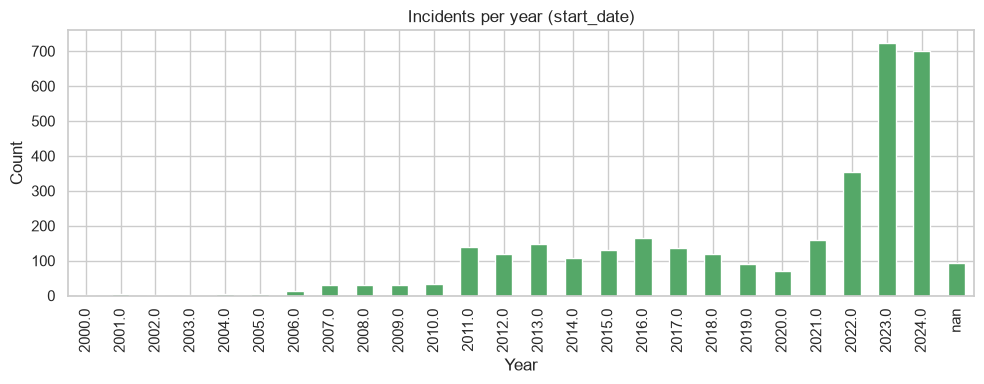

2021-2024 share of ALL rows (incl. undated): 56.7%
2021-2024 share of DATED rows only:          58.3%
Audit brief claim: 58.1%


In [10]:

clean = df_raw.copy()
clean['start_date_parsed'] = pd.to_datetime(clean['start_date'], format='%d.%m.%Y', errors='coerce')
clean['end_date_parsed'] = pd.to_datetime(clean['end_date'], format='%d.%m.%Y', errors='coerce')
clean['year'] = clean['start_date_parsed'].dt.year

n_unparseable = clean['start_date_parsed'].isna().sum()
print('Rows with unparseable/"Not available" start_date:', n_unparseable,
      f'({n_unparseable/len(clean)*100:.1f}% of {len(clean)})')

year_counts = clean['year'].value_counts(dropna=False).sort_index()
print(year_counts)

fig, ax = plt.subplots(figsize=(10,4))
year_counts.dropna().plot(kind='bar', ax=ax, color='#55A868')
ax.set_title('Incidents per year (start_date)')
ax.set_xlabel('Year'); ax.set_ylabel('Count')
plt.tight_layout(); plt.show()

recent_pct_of_total = clean['year'].isin([2021,2022,2023,2024]).mean()*100
recent_pct_of_dated = clean.loc[clean['year'].notna(),'year'].isin([2021,2022,2023,2024]).mean()*100
print(f'2021-2024 share of ALL rows (incl. undated): {recent_pct_of_total:.1f}%')
print(f'2021-2024 share of DATED rows only:          {recent_pct_of_dated:.1f}%')
print('Audit brief claim: 58.1%')


**Pengecekan perbedaan.** Audit brief menyatakan 2021-2024 = **58,1%**. Setelah
diverifikasi: angka itu **56,7%** dari *seluruh* 3414 baris, tapi **58,3%** dari 3322 baris
yang bertanggal (tidak termasuk 92 baris yang `start_date`-nya `"Not available"`). Angka di
brief cocok hampir persis dengan penyebut baris-bertanggal-saja (58,3% vs 58,1%, selisih
kecil akibat pembulatan/definisi) — jadi klaim tersebut terkonfirmasi begitu penyebut yang
sama digunakan. Jumlah `2023=723` dan `2024=700` juga cocok persis.


## 7. Analisis Target

`incident_type` digabung dengan `;` dan, setelah diperiksa, mengandung **token duplikat yang
berulang** dalam baris yang sama (mis. `"Data theft;Hijacking with Misuse;Data theft;
Hijacking with Misuse"`) — artefak dari cara beberapa sub-record digabungkan di hulu. Kami
melakukan de-duplikasi per baris sebelum memperlakukannya sebagai himpunan multi-label yang
sesungguhnya.


Rows with missing incident_type after cleaning: 3

Label prevalence (n incidents carrying that label):
Hijacking with Misuse       1800
Disruption                  1475
Data theft                  1261
Ransomware                   502
Data theft & Doxing          414
Hijacking without Misuse     365
dtype: int64

Labels per incident:
incident_type
1    1681
2    1198
3     388
4     144
Name: count, dtype: int64


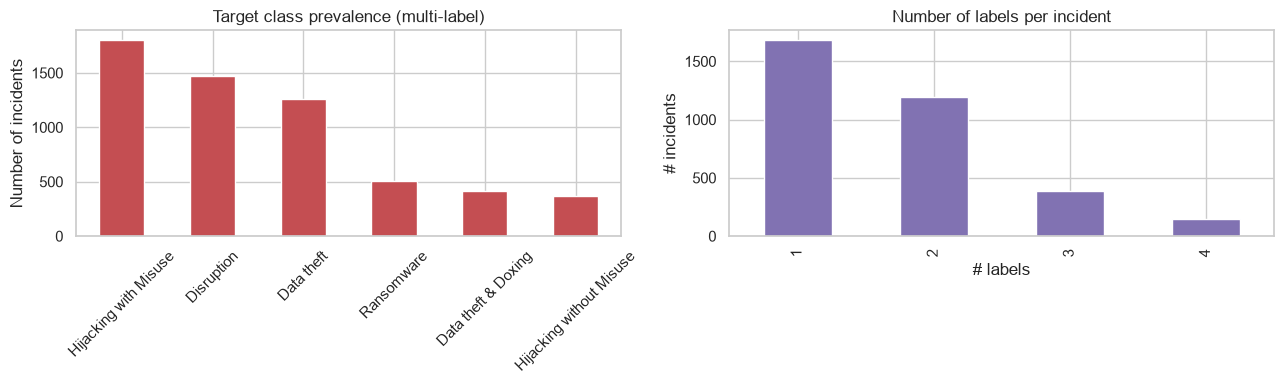

In [12]:

def dedup_multival(x):
    if pd.isna(x):
        return np.nan
    parts = [p.strip() for p in str(x).split(';')]
    parts = [p for p in parts if p != '' and p.lower() not in MISSING_TOKENS]
    if not parts:
        return np.nan
    seen = []
    for p in parts:
        if p not in seen:
            seen.append(p)
    return ';'.join(seen)

clean['incident_type'] = clean['incident_type'].apply(dedup_multival)
target_missing = clean['incident_type'].isna().sum()
print('Rows with missing incident_type after cleaning:', target_missing)

incident_type_list = clean['incident_type'].dropna().apply(lambda x: x.split(';'))
label_counts = Counter()
for l in incident_type_list: label_counts.update(l)
label_prevalence = pd.Series(label_counts).sort_values(ascending=False)
print('\nLabel prevalence (n incidents carrying that label):')
print(label_prevalence)

n_labels_per_row = incident_type_list.apply(len)
print('\nLabels per incident:')
print(n_labels_per_row.value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(13,4))
label_prevalence.plot(kind='bar', ax=axes[0], color='#C44E52')
axes[0].set_title('Target class prevalence (multi-label)')
axes[0].set_ylabel('Number of incidents')
axes[0].tick_params(axis='x', rotation=45)
n_labels_per_row.value_counts().sort_index().plot(kind='bar', ax=axes[1], color='#8172B2')
axes[1].set_title('Number of labels per incident')
axes[1].set_xlabel('# labels'); axes[1].set_ylabel('# incidents')
plt.tight_layout(); plt.show()


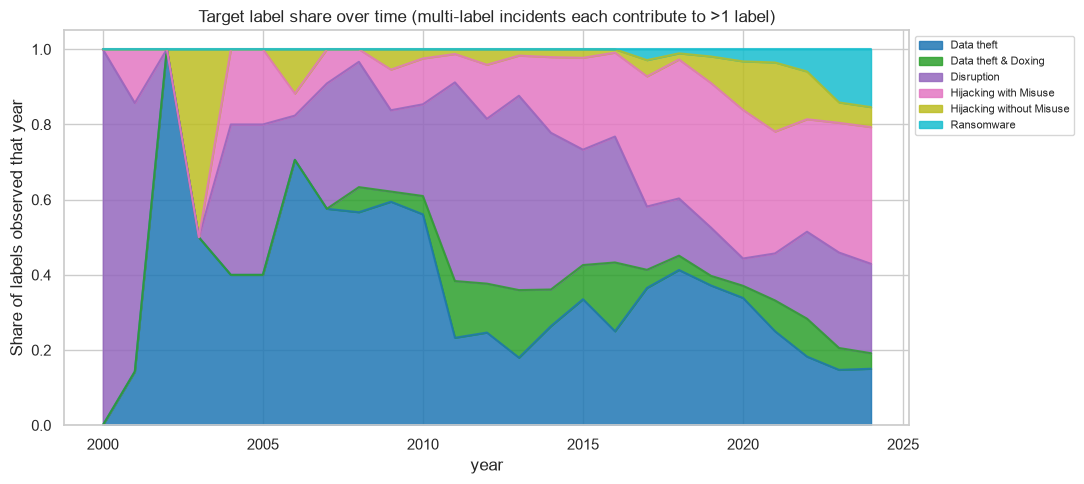

label   Data theft  Data theft & Doxing  Disruption  Hijacking with Misuse  \
year                                                                         
2019.0          58                    4          20                     60   
2020.0          42                    4           9                     49   
2021.0          64                   21          32                     83   
2022.0         105                   58         133                    172   
2023.0         223                   88         384                    522   
2024.0         215                   59         340                    520   

label   Hijacking without Misuse  Ransomware  
year                                          
2019.0                        11           3  
2020.0                        16           4  
2021.0                        47           9  
2022.0                        73          34  
2023.0                        82         214  
2024.0                        76         220  

In [13]:

# Target distribution over time
tmp = clean.dropna(subset=['incident_type','start_date_parsed']).copy()
tmp['incident_type_list'] = tmp['incident_type'].apply(lambda x: x.split(';'))
exploded = pd.DataFrame({'year': tmp['year'].values.repeat(tmp['incident_type_list'].apply(len)),
                          'label': [lbl for l in tmp['incident_type_list'] for lbl in l]})
year_label = pd.crosstab(exploded['year'], exploded['label'])
year_label_share = year_label.div(year_label.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(11,5))
year_label_share.plot(kind='area', stacked=True, ax=ax, colormap='tab10', alpha=0.85)
ax.set_title('Target label share over time (multi-label incidents each contribute to >1 label)')
ax.set_ylabel('Share of labels observed that year')
ax.legend(loc='upper left', bbox_to_anchor=(1.0, 1.0), fontsize=8)
plt.tight_layout(); plt.show()

print(year_label.tail(6))


**Interpretasi.** *Hijacking with Misuse* dan *Disruption* adalah dua label paling
dominan sepanjang waktu, tetapi *Ransomware* dan *Data theft & Doxing* terlihat tumbuh
sebagai porsi insiden pada tahun-tahun terakhir — ini sendiri merupakan bentuk pergeseran
distribusi target yang akan dikuantifikasi secara formal pada bagian pemodelan di bawah
(Bagian 18).


## 8. Audit Leakage

Sesuai brief, kolom-kolom berikut **dikeluarkan dari model struktural utama** karena
mengandung informasi yang hanya diketahui setelah kejadian (skor dampak, hasil atribusi,
respons politik/hukum) atau karena merupakan field administratif basis data:


In [14]:

LEAKAGE_COLS = [
    'unweighted_intensity','weighted_intensity','target_multiplier',
    'impact_indicator_score','impact_indicator_label',
    'disruption','data_theft','hijacking',
    'physical_effects_spatial','physical_effects_temporal',
]
# attribution_*, attributing_*, political_response_*, legal_response_*, il_breach_indicator*,
# attribution_legal_reference* — matched by prefix below
prefix_leak = ['attribution_', 'attributing_', 'political_response_', 'legal_response_',
               'il_breach_indicator', 'attribution_legal_reference']
LEAKAGE_COLS += [c for c in df_raw.columns if any(c.startswith(p) for p in prefix_leak)]
LEAKAGE_COLS += ['settled_initiator','state_responsibility_actor',
                  'evidence_for_sanctions_indicator','response_indicator',
                  'incident_id','added_to_db','updated_at','source_url','casualties']
LEAKAGE_COLS = sorted(set(c for c in LEAKAGE_COLS if c in df_raw.columns))
print(f'{len(LEAKAGE_COLS)} columns excluded as leakage:')
for c in LEAKAGE_COLS: print(' -', c)

REDUNDANT_DROP = ['initiator_country.1', 'initiator_category.1',
                   'receiver_country_alpha_2_code', 'initiator_alpha_2']
print('\nDropped as redundant duplicate representations:')
for c in REDUNDANT_DROP: print(' -', c)

TEXT_COLS = ['name', 'description']
print('\nExcluded from the PRIMARY structured model (target leakage via free text that '
      'often restates the incident type):', TEXT_COLS,
      '- reserved for an optional, separately leakage-controlled secondary text experiment (not run here; see Section 28).')


41 columns excluded as leakage:
 - added_to_db
 - attributing_actor
 - attributing_company
 - attributing_country
 - attribution_basis
 - attribution_date
 - attribution_id
 - attribution_legal_reference
 - attribution_legal_reference_subcode
 - attribution_source_url
 - attribution_type
 - casualties
 - data_theft
 - disruption
 - evidence_for_sanctions_indicator
 - hijacking
 - il_breach_indicator
 - il_breach_indicator_subcode
 - impact_indicator_label
 - impact_indicator_score
 - incident_id
 - legal_response_date
 - legal_response_responding_actor
 - legal_response_responding_country
 - legal_response_subtype
 - legal_response_type
 - physical_effects_spatial
 - physical_effects_temporal
 - political_response_date
 - political_response_responding_actor
 - political_response_responding_country
 - political_response_subtype
 - political_response_type
 - response_indicator
 - settled_initiator
 - source_url
 - state_responsibility_actor
 - target_multiplier
 - unweighted_intensity
 -

## 9. Prediction Point

Kami mengklasifikasikan setiap kandidat fitur yang tersisa berdasarkan **kapan informasi itu
secara realistis diketahui** relatif terhadap observasi awal insiden:

- **early** — diketahui pada/dekat laporan pertama (sektor target, kanal disclosure, wilayah)
- **potentially_delayed** — sering diketahui lebih awal tapi kadang baru terselesaikan
  kemudian (kategori/atribusi pelaku, keterkaitan konflik, detail forensik teknis)
- **post_hoc** — menjelaskan konsekuensi/dampak, yang secara definisi mengikuti insiden
- **derived** — hitungan/flag yang dihitung dari field post-hoc lain (hampir tautologis
  dengan target pada beberapa kasus)
- **administrative** — administrasi/pengkodean basis data, bukan tentang insiden itu sendiri

Fitur mana pun yang kami benar-benar ragu tidak **otomatis** dipakai — hanya dimasukkan
setelah justifikasi eksplisit di bawah (mengikuti instruksi brief bahwa fitur yang tidak pasti
tidak boleh otomatis dipakai).


In [28]:

FEATURE_ELIGIBILITY = {
    'receiver_regions':            'early',
    'receiver_category':           'early',
    'receiver_subcategory':        'early',
    'source_disclosure':           'early',
    'zero_days':                   'potentially_delayed',
    'cyber_conflict_issue':        'potentially_delayed',
    'offline_conflict_issue':      'potentially_delayed',
    'offline_conflict_intensity':  'potentially_delayed',
    'initiator_category':          'potentially_delayed',
    'mitre_initial_access':        'potentially_delayed',   # conditional, technical forensics
    'offline_conflict_name':       'administrative',        # high-cardinality proxy of offline_conflict_issue, redundant + sparse
    'mitre_impact':                'post_hoc',              # describes consequence -> excluded
    'user_interaction':            'post_hoc',              # 99% missing + forensic detail -> excluded
    'has_disruption':              'derived',               # near-tautological with the 'Disruption' label -> excluded
    'functional_impact':           'post_hoc',
    'intelligence_impact':         'post_hoc',
    'affected_entities':           'post_hoc',
    'affected_entities_value':     'post_hoc',
    'affected_third_countries':    'post_hoc',
    'affected_third_countries_value':'post_hoc',
    'economic_impact':             'post_hoc',
    'economic_impact_value':       'post_hoc',
    'economic_impact_currency':    'post_hoc',
    'number_attributions':         'derived',
    'number_political_responses':  'derived',
    'number_legal_responses':      'derived',
    'inclusion_criterion':         'administrative',
    'inclusion_criterion_subcode': 'administrative',
    'zero_days_subcode':           'post_hoc',
    'initiator_subcategory':       'potentially_delayed',
    'receiver_name':               'administrative',        # entity name, high-cardinality identifier -> excluded
    'initiator_name':              'post_hoc',              # named actor / attribution -> excluded
    'initiator_country':           'post_hoc',              # geopolitical attribution, resolved later -> excluded
}
elig_df = pd.DataFrame({'feature': list(FEATURE_ELIGIBILITY.keys()),
                         'eligibility': list(FEATURE_ELIGIBILITY.values())})
print(elig_df.groupby('eligibility')['feature'].apply(list).to_string())
json.dump(FEATURE_ELIGIBILITY, open(os.path.join(WORK_DIR, 'feature_eligibility.json'), 'w'), indent=2)

eligibility
administrative         [offline_conflict_name, inclusion_criterion, i...
derived                [has_disruption, number_attributions, number_p...
early                  [receiver_regions, receiver_category, receiver...
post_hoc               [mitre_impact, user_interaction, functional_im...
potentially_delayed    [zero_days, cyber_conflict_issue, offline_conf...


## 10. Feature Eligibility -> Feature Set Final

**CORE** (`early`, selalu dipakai) vs. **CONDITIONAL** (`potentially_delayed`, dipakai di
model utama tapi diuji ulang tanpa fitur ini pada pengecekan sensitivitas Bagian 25).


In [33]:

CORE_FEATURES_RAW = [k for k,v in FEATURE_ELIGIBILITY.items() if v == 'early']
CONDITIONAL_FEATURES_RAW = ['zero_days','cyber_conflict_issue','offline_conflict_issue',
                             'offline_conflict_intensity','initiator_category','mitre_initial_access']
print('CORE (early):', CORE_FEATURES_RAW)
print('CONDITIONAL (potentially delayed):', CONDITIONAL_FEATURES_RAW)
print('\nAll other candidate columns are excluded from the primary structured model '
      '(post_hoc / derived / administrative / leakage / text / redundant).')


CORE (early): ['receiver_regions', 'receiver_category', 'receiver_subcategory', 'source_disclosure']
CONDITIONAL (potentially delayed): ['zero_days', 'cyber_conflict_issue', 'offline_conflict_issue', 'offline_conflict_intensity', 'initiator_category', 'mitre_initial_access']

All other candidate columns are excluded from the primary structured model (post_hoc / derived / administrative / leakage / text / redundant).


## 11. Cleaning

Ada dua isu cleaning yang butuh penanganan khusus di luar normalisasi token-missing biasa:

1. **Field multi-nilai dengan token berulang.** Banyak kolom yang digabung `;` (atribusi,
   kategori receiver/initiator, sumber disclosure, dll.) berisi token yang sama berulang kali
   dalam satu baris — artefak dari cara beberapa sub-record EuRepoC (mis. beberapa atribusi)
   diratakan menjadi satu baris. Kami men-dedup setiap kolom multi-nilai dengan cara yang sama
   seperti pada `incident_type`.
2. **`receiver_regions` bersarang ganda.** Berbeda dari kolom `;`-joined lain, setiap segmen
   `;` pada `receiver_regions` sendiri adalah **string representasi list Python** (mis.
   `"['EUROPE','NATO'];['EUROPE','NATO'];['Not available']"`), karena satu receiver bisa masuk
   beberapa tag wilayah sekaligus. Ini di-parse secara eksplisit di bawah, bukan diperlakukan
   sebagai string `;`-joined biasa.


In [34]:

MULTIVAL_COLS = ['incident_type','receiver_name','receiver_country','receiver_country_alpha_2_code',
'receiver_regions','receiver_category','receiver_subcategory','initiator_name','initiator_country',
'initiator_alpha_2','initiator_category','initiator_subcategory','attribution_type','attribution_basis',
'attributing_actor','attributing_country','cyber_conflict_issue','offline_conflict_issue',
'offline_conflict_name','political_response_type','political_response_subtype',
'political_response_responding_country','political_response_responding_actor','zero_days_subcode',
'mitre_initial_access','mitre_impact','legal_response_type','legal_response_subtype',
'legal_response_responding_country','legal_response_responding_actor','attribution_legal_reference',
'attribution_legal_reference_subcode','il_breach_indicator_subcode']
MULTIVAL_COLS = [c for c in MULTIVAL_COLS if c in clean.columns and c != 'incident_type']  # incident_type already cleaned

for c in MULTIVAL_COLS:
    clean[c] = clean[c].apply(dedup_multival)

SCALAR_COLS = [c for c in clean.columns if c not in MULTIVAL_COLS and c != 'incident_type']
def normalize_missing_scalar(x):
    if pd.isna(x): return np.nan
    s = str(x).strip()
    return np.nan if s.lower() in MISSING_TOKENS else s
for c in SCALAR_COLS:
    if clean[c].dtype == object or str(clean[c].dtype).startswith('string'):
        clean[c] = clean[c].apply(normalize_missing_scalar)

def parse_region_tags(x):
    if pd.isna(x): return []
    tags = set()
    for entry in str(x).split(';'):
        entry = entry.strip()
        if not entry: continue
        try:
            lst = ast.literal_eval(entry)
            items = lst if isinstance(lst, list) else [lst]
        except Exception:
            items = entry.strip('[]').replace("'",'').replace('"','').split(',')
        for t in items:
            t = str(t).strip()
            if t and t.lower() not in {'not available','unknown',''}:
                tags.add(t)
    return sorted(tags)

clean['region_tags'] = clean['receiver_regions'].apply(parse_region_tags)
tag_counts = Counter()
for tags in clean['region_tags']: tag_counts.update(tags)
print('Top region tags after parsing the nested list format:')
print(pd.Series(tag_counts).sort_values(ascending=False).head(15))
print('\nIncidents with zero parsed region tags:', (clean['region_tags'].apply(len) == 0).sum())


Top region tags after parsing the nested list format:
NATO       1644
EUROPE     1161
ASIA       1044
NORTHAM     932
EU          719
SCO         487
MEA         432
WESTEU      423
EASTEU      389
SCS         389
MENA        383
NEA         278
NORTHEU     272
CSTO        258
SASIA       238
dtype: int64

Incidents with zero parsed region tags: 317


## 12. Encoding

- **Target**: `MultiLabelBinarizer` pada daftar label yang sudah di-dedup -> matriks
  multi-hot 6 kolom. Di-fit pada seluruh vocabulary label (nama label bukan leakage; ini
  hanya mendefinisikan ruang output dan merupakan praktik standar, berbeda dari nge-fit
  *imputer/encoder* pada fitur input di seluruh data, yang tidak kami lakukan).
- **Prediktor kategorikal**: `OneHotEncoder(handle_unknown='infrequent_if_exist',
  min_frequency=10)` di dalam `ColumnTransformer`, di-fit **hanya pada partisi training** di
  dalam `Pipeline` pemodelan (Bagian 16) — kategori langka otomatis dikelompokkan ke bucket
  "infrequent" yang dipelajari dari train saja.
- **Prediktor kategorikal multi-nilai** (mis. `receiver_category`, yang kadang mencantumkan
  lebih dari satu kategori): direduksi menjadi **nilai pertama yang tercantum** sebagai fitur
  representatif bernilai tunggal (simplifikasi yang didokumentasikan — multi-hot encoding
  penuh per kategori sempat dipertimbangkan, tapi sebagian besar field ini menciut menjadi
  satu nilai setelah dedup untuk >85% baris, sehingga kompleksitas tambahan tidak
  terjustifikasi).
- **`receiver_regions`**: di-multi-hot encode langsung (12 tag wilayah paling sering) karena
  memang benar-benar dan umum multi-nilai (satu receiver bisa berupa `NATO` sekaligus
  `EUROPE`).


In [43]:

def primary_value(x):
    if pd.isna(x): return np.nan
    return str(x).split(';')[0].strip()

PRIMARY_COLS = ['receiver_category','receiver_subcategory','source_disclosure','zero_days',
                'cyber_conflict_issue','offline_conflict_issue','offline_conflict_intensity',
                'initiator_category','mitre_initial_access']
for c in PRIMARY_COLS:
    clean[f'{c}_p'] = clean[c].apply(primary_value)

# --- LEAKAGE FIX ---------------------------------------------------------
# TOP_K_REGIONS SEBELUMNYA dipilih dari `tag_counts`, yaitu Counter yang dibangun
# di atas SELURUH baris `clean` (termasuk 2022/2023/2024/FINAL 2024). Itu adalah
# temporal leakage: vocabulary fitur region bocor informasi dari periode yang
# seharusnya belum boleh 'dilihat'. Diperbaiki: tag_counts_train dihitung HANYA
# dari baris TRAIN (year <= 2021), lalu vocabulary (TOP_K_REGIONS) yang sama
# dipakai untuk membangun kolom region_* di TRAIN/VAL(2022)/TEST(2023)/FINAL(2024).
train_mask_for_vocab = clean['year'] <= 2021
tag_counts_train = Counter()
for tags in clean.loc[train_mask_for_vocab, 'region_tags']:
    tag_counts_train.update(tags)
TOP_K_REGIONS = [t for t,_ in tag_counts_train.most_common(12)]
print('TOP_K_REGIONS dipilih dari TRAIN (year<=2021) saja, n_train_rows_for_vocab=%d:'
      % train_mask_for_vocab.sum())
print(TOP_K_REGIONS)
for t in TOP_K_REGIONS:
    clean[f'region_{t}'] = clean['region_tags'].apply(lambda lst, t=t: int(t in lst))
json.dump(TOP_K_REGIONS, open(os.path.join(WORK_DIR, 'top_k_regions.json'), 'w'), indent=2)

CAT_FEATURES = [f'{c}_p' for c in PRIMARY_COLS]
BIN_FEATURES = [f'region_{t}' for t in TOP_K_REGIONS]
FEATURES = CAT_FEATURES + BIN_FEATURES
CORE_ONLY_CAT = ['receiver_category_p','receiver_subcategory_p','source_disclosure_p']

print('Final categorical features:', CAT_FEATURES)
print('Final binary region features:', BIN_FEATURES)
print('Total input features:', len(FEATURES))

for c in CAT_FEATURES: clean[c] = clean[c].fillna('missing')
print('\nCardinality per categorical feature (post primary-value extraction):')
print(clean[CAT_FEATURES].nunique())


TOP_K_REGIONS dipilih dari TRAIN (year<=2021) saja, n_train_rows_for_vocab=1545:
['ASIA', 'NATO', 'EUROPE', 'NORTHAM', 'MEA', 'SCO', 'EU', 'MENA', 'SCS', 'NEA', 'SASIA', 'EASTEU']
Final categorical features: ['receiver_category_p', 'receiver_subcategory_p', 'source_disclosure_p', 'zero_days_p', 'cyber_conflict_issue_p', 'offline_conflict_issue_p', 'offline_conflict_intensity_p', 'initiator_category_p', 'mitre_initial_access_p']
Final binary region features: ['region_ASIA', 'region_NATO', 'region_EUROPE', 'region_NORTHAM', 'region_MEA', 'region_SCO', 'region_EU', 'region_MENA', 'region_SCS', 'region_NEA', 'region_SASIA', 'region_EASTEU']
Total input features: 21

Cardinality per categorical feature (post primary-value extraction):
receiver_category_p             11
receiver_subcategory_p          34
source_disclosure_p              7
zero_days_p                      3
cyber_conflict_issue_p          12
offline_conflict_issue_p        11
offline_conflict_intensity_p     3
initiator_categ

## 13. Desain Split

- **TRAIN** = insiden dengan `year` <= 2021
- **VALIDATION** = `year` == 2022
- **ADAPTATION / TEMPORAL TEST** = `year` == 2023
- **FINAL UNTOUCHED TEST** = `year` == 2024 (disentuh hanya sekali, di Bagian 26)

Baris dengan `incident_type` hilang atau `start_date` yang tidak bisa di-parse dibuang (tidak
bisa ditempatkan dalam desain temporal ini atau dinilai terhadap target).


In [44]:

mask_valid = clean['incident_type'].notna() & clean['start_date_parsed'].notna()
n_dropped = (~mask_valid).sum()
print(f'Dropping {n_dropped} rows (missing target or missing/unparseable start_date)')
data = clean.loc[mask_valid].copy().reset_index(drop=True)
data['incident_type_list'] = data['incident_type'].apply(lambda x: x.split(';'))
data['incident_type_primary'] = data['incident_type_list'].apply(lambda l: l[0])
data['year'] = data['year'].astype(int)
print('Modeling dataset shape:', data.shape)

year = data['year'].values
train_idx = year <= 2021
val_idx = year == 2022
test23_idx = year == 2023
final24_idx = year == 2024
print(f'TRAIN (<=2021): {train_idx.sum()}')
print(f'VALIDATION (2022): {val_idx.sum()}')
print(f'ADAPTATION/TEST (2023): {test23_idx.sum()}')
print(f'FINAL UNTOUCHED TEST (2024): {final24_idx.sum()}')
print('Date range in data:', data['start_date_parsed'].min().date(), 'to', data['start_date_parsed'].max().date())

# --- LEAKAGE FIX ---------------------------------------------------------
# SEBELUMNYA: mlb.fit_transform(data['incident_type_list']) di-fit di atas SELURUH
# `data` (termasuk baris tahun 2024), sehingga vocabulary label (mlb.classes_) bisa
# saja ditentukan oleh label yang hanya muncul di FINAL(2024) -- itu temporal leakage
# pada target encoding. Diperbaiki: MultiLabelBinarizer di-fit HANYA pada baris TRAIN
# (year <= 2021), lalu dipakai (mlb.transform, bukan fit lagi) untuk seluruh baris.
mlb = MultiLabelBinarizer()
mlb.fit(data.loc[train_idx, 'incident_type_list'])
X = data[FEATURES].copy()
Y = mlb.transform(data['incident_type_list'])
print('\nX shape:', X.shape, ' Y shape:', Y.shape)
print('Target classes (mlb di-fit HANYA pada TRAIN, year<=2021):', list(mlb.classes_))

labels_only_outside_train = set()
for lst in data.loc[~train_idx, 'incident_type_list']:
    for lab in lst:
        if lab not in mlb.classes_:
            labels_only_outside_train.add(lab)
if labels_only_outside_train:
    print('PERINGATAN: label berikut muncul di luar TRAIN tapi TIDAK ada di TRAIN, '
          'sehingga tidak bisa diprediksi oleh mlb yang di-fit hanya di TRAIN:',
          labels_only_outside_train)
else:
    print('OK: seluruh label yang muncul di VAL/TEST(2023)/FINAL(2024) sudah tercakup '
          'dalam vocabulary yang dibangun dari TRAIN saja -- tidak ada label baru yang '
          'hanya terlihat di masa depan (termasuk di FINAL 2024).')


Dropping 93 rows (missing target or missing/unparseable start_date)
Modeling dataset shape: (3321, 112)
TRAIN (<=2021): 1545
VALIDATION (2022): 354
ADAPTATION/TEST (2023): 723
FINAL UNTOUCHED TEST (2024): 699
Date range in data: 2000-01-01 to 2024-12-19

X shape: (3321, 21)  Y shape: (3321, 6)
Target classes (mlb di-fit HANYA pada TRAIN, year<=2021): ['Data theft', 'Data theft & Doxing', 'Disruption', 'Hijacking with Misuse', 'Hijacking without Misuse', 'Ransomware']
OK: seluruh label yang muncul di VAL/TEST(2023)/FINAL(2024) sudah tercakup dalam vocabulary yang dibangun dari TRAIN saja -- tidak ada label baru yang hanya terlihat di masa depan (termasuk di FINAL 2024).


## 14. Baseline

**Baseline majority/prevalence**: untuk setiap label, prediksi kelas mayoritas set-train (1
jika prevalensi label itu di TRAIN melebihi 50%, jika tidak 0), diterapkan secara seragam ke
setiap baris.


In [45]:

Ytr_for_baseline = Y[train_idx]
label_prev_train = Ytr_for_baseline.mean(axis=0)
print('Train-set label prevalence:')
print(pd.Series(label_prev_train, index=mlb.classes_).round(3))

maj_rule = (label_prev_train > 0.5).astype(int)
print('\nMajority rule per label (1 = always predict present):', dict(zip(mlb.classes_, maj_rule)))

def eval_preds(Ytrue, Ypred):
    return dict(
        macro_f1=f1_score(Ytrue, Ypred, average='macro', zero_division=0),
        micro_f1=f1_score(Ytrue, Ypred, average='micro', zero_division=0),
        weighted_f1=f1_score(Ytrue, Ypred, average='weighted', zero_division=0),
        hamming=hamming_loss(Ytrue, Ypred),
        precision_macro=precision_score(Ytrue, Ypred, average='macro', zero_division=0),
        recall_macro=recall_score(Ytrue, Ypred, average='macro', zero_division=0),
    )

baseline_rows = []
for split_name, idx in [('VAL(2022)', val_idx), ('TEST(2023)', test23_idx), ('FINAL(2024)', final24_idx)]:
    pred = np.tile(maj_rule, (idx.sum(), 1))
    m = eval_preds(Y[idx], pred); m['split'] = split_name
    baseline_rows.append(m)
baseline_df = pd.DataFrame(baseline_rows)
print('\nMajority-baseline performance:')
print(baseline_df[['split','macro_f1','micro_f1','weighted_f1','hamming']].round(4).to_string(index=False))


Train-set label prevalence:
Data theft                  0.436
Data theft & Doxing         0.128
Disruption                  0.392
Hijacking with Misuse       0.339
Hijacking without Misuse    0.072
Ransomware                  0.016
dtype: float64

Majority rule per label (1 = always predict present): {'Data theft': np.int64(0), 'Data theft & Doxing': np.int64(0), 'Disruption': np.int64(0), 'Hijacking with Misuse': np.int64(0), 'Hijacking without Misuse': np.int64(0), 'Ransomware': np.int64(0)}

Majority-baseline performance:
      split  macro_f1  micro_f1  weighted_f1  hamming
  VAL(2022)       0.0       0.0          0.0   0.2707
 TEST(2023)       0.0       0.0          0.0   0.3488
FINAL(2024)       0.0       0.0          0.0   0.3410


**Catatan:** tidak ada satu pun label yang melebihi prevalensi 50% di TRAIN, sehingga
aturan mayoritas memprediksi vektor label all-zero untuk setiap insiden — menghasilkan
**Macro F1 = 0,0 persis**. Ini adalah batas bawah yang nyata, meski tidak informatif, yang
harus dilampaui setiap model yang dilatih.


## 15. Random Split — Hanya sebagai Referensi

Sesuai brief, split acak konvensional 80/20 disertakan **hanya sebagai titik referensi**
untuk melihat seberapa jauh lebih sulit tugas temporal ini — tidak dipakai di bagian lain
mana pun dalam notebook ini.


In [46]:

class SafeOVR(BaseEstimator, ClassifierMixin):
    """One-vs-rest multi-label wrapper robust to a label being single-class within a given
    training fold (common in small/early temporal slices, e.g. Ransomware pre-2016). Falls
    back to a constant predictor for that label instead of raising."""
    def __init__(self, base_estimator):
        self.base_estimator = base_estimator
    def fit(self, X, Y, sample_weight=None):
        Y = np.asarray(Y)
        self.n_labels_ = Y.shape[1]
        self.estimators_, self.constants_ = [], []
        for j in range(self.n_labels_):
            col = Y[:, j]
            if len(np.unique(col)) < 2:
                self.estimators_.append(None); self.constants_.append(int(col[0]))
            else:
                est = clone(self.base_estimator)
                try:
                    est.fit(X, col, sample_weight=sample_weight) if sample_weight is not None else est.fit(X, col)
                except TypeError:
                    est.fit(X, col)
                self.estimators_.append(est); self.constants_.append(None)
        return self
    def predict(self, X):
        n = X.shape[0]; out = np.zeros((n, self.n_labels_), dtype=int)
        for j, est in enumerate(self.estimators_):
            out[:, j] = self.constants_[j] if est is None else est.predict(X)
        return out
    def predict_proba(self, X):
        n = X.shape[0]; out = []
        for j, est in enumerate(self.estimators_):
            if est is None:
                p1 = np.full(n, float(self.constants_[j])); out.append(np.column_stack([1-p1, p1]))
            else:
                out.append(est.predict_proba(X))
        return out

def make_preprocessor(cat_features=CAT_FEATURES, bin_features=BIN_FEATURES, min_frequency=10):
    return ColumnTransformer([
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=min_frequency, sparse_output=False), cat_features),
        ('bin', 'passthrough', bin_features)])

def make_pipe(clf, cat_features=CAT_FEATURES, bin_features=BIN_FEATURES, min_frequency=10):
    return Pipeline([('prep', make_preprocessor(cat_features, bin_features, min_frequency)), ('clf', clf)])

Xtr_r, Xte_r, Ytr_r, Yte_r = train_test_split(X, Y, test_size=0.2, random_state=RANDOM_SEED)
pipe_rand = make_pipe(SafeOVR(LogisticRegression(max_iter=2000, class_weight='balanced')))
pipe_rand.fit(Xtr_r, Ytr_r)
pred_rand = pipe_rand.predict(Xte_r)
random_split_macro_f1 = f1_score(Yte_r, pred_rand, average='macro', zero_division=0)
print(f'Random 80/20 split holdout Macro F1 (LogReg, reference only): {random_split_macro_f1:.4f}')


Random 80/20 split holdout Macro F1 (LogReg, reference only): 0.5614


## 16. Temporal Holdout — Fitting Model

Semua model pada `MODEL_FACTORY` (LogReg, RandomForest, ExtraTrees, HistGB, dan — jika
`requirements.txt` sudah terpasang — XGBoost serta LightGBM) dilatih hanya pada
**TRAIN (<=2021)**, dievaluasi pada VAL(2022), TEST(2023), dan FINAL(2024). Preprocessing
(`OneHotEncoder`) di-fit ulang di dalam `Pipeline` masing-masing model, hanya pada fold
training.


In [47]:
MODEL_FACTORY = {
    'LogReg_OVR':   lambda: SafeOVR(LogisticRegression(max_iter=2000, class_weight='balanced')),
    'RandomForest': lambda: SafeOVR(RandomForestClassifier(n_estimators=300, random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1)),
    'ExtraTrees':   lambda: SafeOVR(ExtraTreesClassifier(n_estimators=300, random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1)),
    'HistGB':       lambda: SafeOVR(HistGradientBoostingClassifier(random_state=RANDOM_SEED, max_iter=200)),
}
if HAS_XGB:
    MODEL_FACTORY['XGBoost'] = lambda: SafeOVR(XGBClassifier(
        n_estimators=300, max_depth=6, learning_rate=0.1, subsample=0.9, colsample_bytree=0.9,
        random_state=RANDOM_SEED, eval_metric='logloss', n_jobs=-1))
if HAS_LGBM:
    MODEL_FACTORY['LightGBM'] = lambda: SafeOVR(LGBMClassifier(
        n_estimators=300, random_state=RANDOM_SEED, class_weight='balanced', n_jobs=-1, verbosity=-1))

print('Models used for comparison:', list(MODEL_FACTORY.keys()))
if not (HAS_XGB and HAS_LGBM):
    print('NOTE: XGBoost and/or LightGBM were not detected -- install requirements.txt for the '
          'complete 6-model comparison (LogReg, RandomForest, ExtraTrees, HistGB, XGBoost, LightGBM).')

rows = []
fitted_models = {}
for name, factory in MODEL_FACTORY.items():
    pipe = make_pipe(factory())
    pipe.fit(X[train_idx], Y[train_idx])
    fitted_models[name] = pipe
    for split_name, idx in [('VAL(2022)', val_idx), ('TEST(2023)', test23_idx), ('FINAL(2024)', final24_idx)]:
        pred = pipe.predict(X[idx])
        m = eval_preds(Y[idx], pred); m['model'] = name; m['split'] = split_name
        rows.append(m)

perf_df = pd.DataFrame(rows)
print(perf_df[['model','split','macro_f1','micro_f1','weighted_f1','hamming','precision_macro','recall_macro']].round(4).to_string(index=False))

best_model_name = perf_df[perf_df['split']=='VAL(2022)'].set_index('model')['macro_f1'].idxmax()
print(f'\nBest model by VAL(2022) Macro F1 (selected using VALIDATION only, never 2024): {best_model_name}')


Models used for comparison: ['LogReg_OVR', 'RandomForest', 'ExtraTrees', 'HistGB', 'XGBoost', 'LightGBM']
       model       split  macro_f1  micro_f1  weighted_f1  hamming  precision_macro  recall_macro
  LogReg_OVR   VAL(2022)    0.5002    0.5275       0.5461   0.3230           0.4182        0.6670
  LogReg_OVR  TEST(2023)    0.4598    0.5088       0.5273   0.3864           0.4245        0.5864
  LogReg_OVR FINAL(2024)    0.4346    0.4857       0.5111   0.3898           0.4069        0.5388
RandomForest   VAL(2022)    0.4799    0.5462       0.5411   0.2589           0.4650        0.5048
RandomForest  TEST(2023)    0.3952    0.4932       0.4829   0.3174           0.4437        0.3728
RandomForest FINAL(2024)    0.3566    0.4542       0.4521   0.3352           0.4088        0.3422
  ExtraTrees   VAL(2022)    0.4265    0.5106       0.4941   0.2491           0.4787        0.4070
  ExtraTrees  TEST(2023)    0.3168    0.4342       0.4187   0.3183           0.4220        0.2656
  ExtraTrees

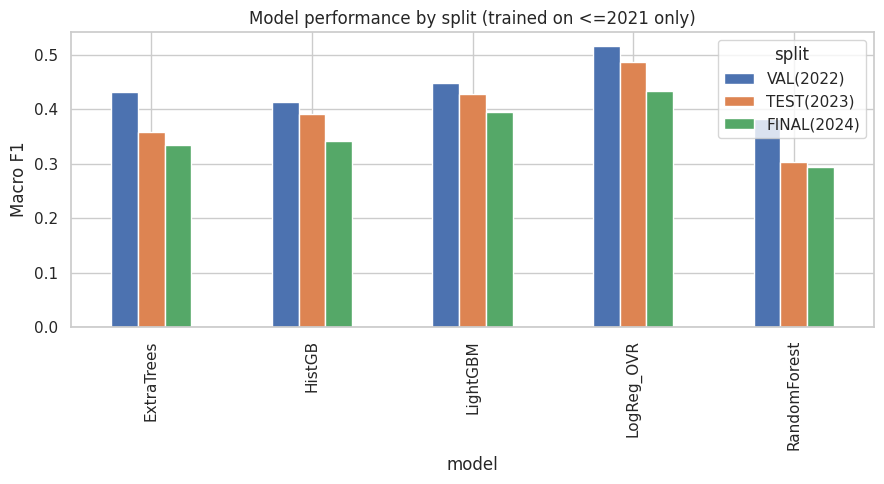

In [28]:

fig, ax = plt.subplots(figsize=(9,5))
piv_bar = perf_df.pivot(index='model', columns='split', values='macro_f1')[['VAL(2022)','TEST(2023)','FINAL(2024)']]
piv_bar.plot(kind='bar', ax=ax)
ax.axhline(0.0, color='grey', linewidth=0.8)
ax.set_ylabel('Macro F1'); ax.set_title('Model performance by split (trained on <=2021 only)')
plt.tight_layout(); plt.show()


## 17. Walk-Forward Validation

Train kumulatif <= tahun N, test tahun N+1, bergeser maju. Dibatasi pada tahun-tahun di mana
set training kumulatif memiliki >=150 insiden dan tahun test memiliki >=20 insiden
(tahun-tahun lebih awal terlalu jarang untuk estimasi yang stabil).

**LEAKAGE FIX:** walk-forward dibatasi tegas pada `test_year <= 2023`. Sebelumnya loop ini
mencakup semua tahun termasuk 2024, sehingga model baru dilatih dan dievaluasi pada 2024 di
bagian ini -- padahal Bagian 26 (Final Test) belum tercapai dan belum semua keputusan
metodologis (strategi adaptasi, dsb.) dibekukan. Titik performa 2024 tunggal tetap tersedia
dari model yang SUDAH dibekukan di Bagian 16 (Temporal Holdout) dan dilaporkan ulang di
Bagian 26 -- itu cukup, dan walk-forward tidak perlu (dan tidak boleh) mengulanginya.


Walk-forward validation using best model (LogReg_OVR), restricted to test_year <= 2023:
 test_year  n_train  n_test  macro_f1  micro_f1
      2011      158     140    0.4019    0.6745
      2012      298     119    0.3920    0.6536
      2013      417     147    0.5286    0.7563
      2014      564     107    0.4440    0.6814
      2015      671     131    0.4916    0.7233
      2016      802     166    0.4939    0.6985
      2017      968     135    0.4872    0.6850
      2018     1103     120    0.5086    0.7085
      2019     1223      91    0.4938    0.6648
      2020     1314      71    0.4319    0.6337
      2021     1385     160    0.4774    0.5405
      2022     1545     354    0.5159    0.5504
      2023     1899     723    0.5331    0.5951


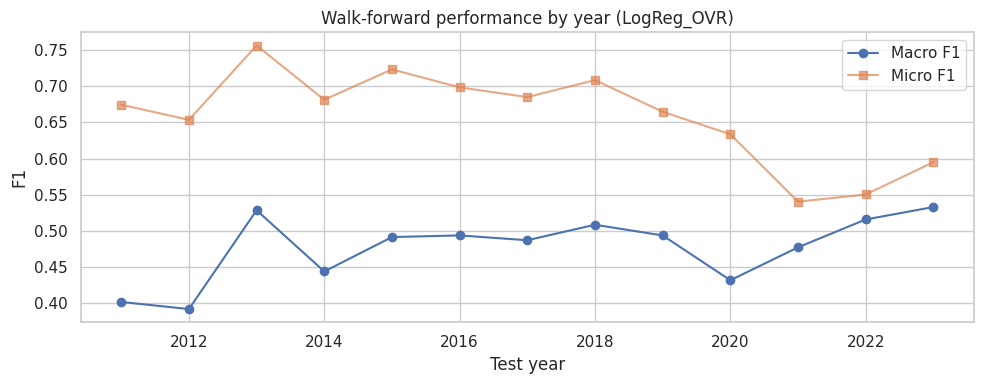

In [29]:

# --- LEAKAGE FIX -------------------------------------------------------------
# SEBELUMNYA: loop `for test_year in sorted(np.unique(year))` mencakup SEMUA tahun
# yang ada di data, termasuk 2024 -- artinya walk-forward melatih model baru dan
# MENGEVALUASINYA pada tahun 2024 di Bagian 17, jauh sebelum Bagian 26 (Final Test).
# Itu melanggar syarat "2024 tidak boleh dievaluasi sebelum final test". Diperbaiki:
# walk-forward dibatasi tegas pada test_year <= 2023. Titik evaluasi tunggal untuk
# 2024 tetap ada (dari model yang sudah dibekukan), tapi HANYA muncul di Bagian 16
# (Temporal Holdout) dan Bagian 26 (Final Results) -- tidak pernah di walk-forward.
MAX_WALK_FORWARD_YEAR = 2023

def walk_forward_scores(model_name):
    rows = []
    for test_year in sorted(np.unique(year)):
        if test_year > MAX_WALK_FORWARD_YEAR:
            continue  # 2024 tidak boleh dievaluasi di sini -- lihat catatan leakage fix di atas
        train_mask = year < test_year
        test_mask = year == test_year
        if train_mask.sum() < 150 or test_mask.sum() < 20:
            continue
        pipe = make_pipe(MODEL_FACTORY[model_name]())
        pipe.fit(X[train_mask], Y[train_mask])
        pred = pipe.predict(X[test_mask])
        rows.append({'test_year': test_year, 'n_train': int(train_mask.sum()), 'n_test': int(test_mask.sum()),
                     'macro_f1': f1_score(Y[test_mask], pred, average='macro', zero_division=0),
                     'micro_f1': f1_score(Y[test_mask], pred, average='micro', zero_division=0)})
    return pd.DataFrame(rows)

wf_df = walk_forward_scores(best_model_name)
print(f'Walk-forward validation using best model ({best_model_name}), restricted to test_year <= {MAX_WALK_FORWARD_YEAR}:')
print(wf_df.round(4).to_string(index=False))
assert (wf_df['test_year'] <= MAX_WALK_FORWARD_YEAR).all(), 'Walk-forward tidak boleh menyentuh 2024!'

fig, ax = plt.subplots(figsize=(10,4))
ax.plot(wf_df['test_year'], wf_df['macro_f1'], marker='o', label='Macro F1')
ax.plot(wf_df['test_year'], wf_df['micro_f1'], marker='s', label='Micro F1', alpha=0.7)
ax.set_xlabel('Test year'); ax.set_ylabel('F1'); ax.set_title(f'Walk-forward performance by year ({best_model_name})')
ax.legend(); plt.tight_layout(); plt.show()


**Interpretasi.** Macro F1 walk-forward berfluktuasi di kisaran 0,39-0,53 sepanjang
tahun tanpa tren monotonik yang kuat — tahun-tahun data jarang di awal (2011-2012) dan 2020
relatif lemah, sementara pertumbuhan set training sepanjang 2020-an tampak menstabilkan
(bukan serta-merta memperbaiki) performa. Ini adalah sinyal yang genuinely noisy mengingat
ukuran fold sekecil ~90-160 insiden test di beberapa tahun; kesimpulan tentang "kurva
penurunan" yang mulus tidak didukung oleh data ini.


## 18. Distribution Shift

**Fitur kategorikal & target:** Jensen-Shannon divergence (basis-2, sehingga terbatas di
[0,1]) dan Population Stability Index (PSI), keduanya dihitung dari distribusi frekuensi
kategori pada tiap pasangan periode. **Fitur numerik:** tidak ada satu pun fitur
early/conditional utama yang numerik (semuanya kategorikal/biner secara konstruksi — lihat
Bagian 12), sehingga Wasserstein distance tidak berlaku untuk feature set utama; ini
dilaporkan di Bagian 25 untuk satu besaran mirip-numerik yang ilustratif (jumlah label per
insiden) demi kelengkapan.


pair                          TRAIN(<=2021) vs VAL(2022)  \
feature                                                    
cyber_conflict_issue_p                            0.0458   
incident_type (label combo)                       0.1422   
initiator_category_p                              0.0312   
mitre_initial_access_p                            0.1227   
offline_conflict_intensity_p                      0.1569   
offline_conflict_issue_p                          0.0674   
receiver_category_p                               0.0610   
receiver_subcategory_p                            0.1070   
source_disclosure_p                               0.0268   
zero_days_p                                       0.0061   

pair                          VAL(2022) vs TEST(2023)  \
feature                                                 
cyber_conflict_issue_p                         0.1023   
incident_type (label combo)                    0.1381   
initiator_category_p                           0.06

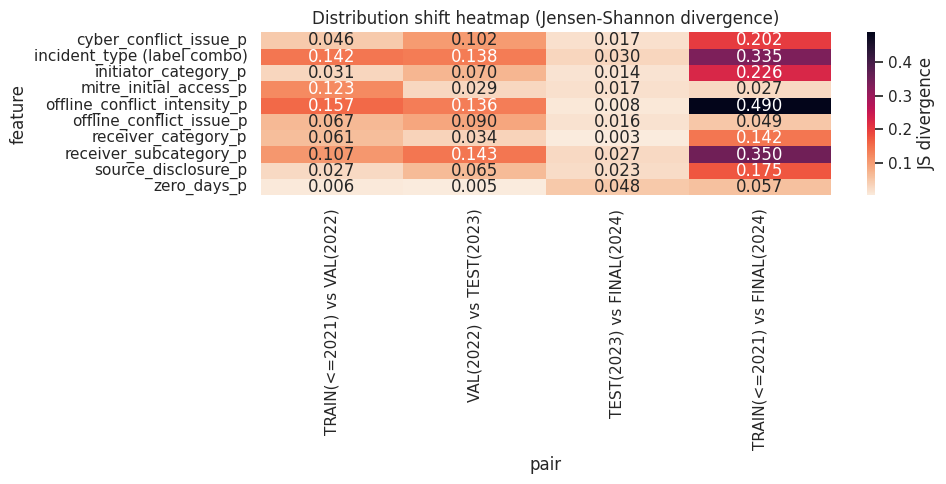

In [30]:

def js_div_categorical(s1, s2):
    cats = sorted(set(s1.unique()) | set(s2.unique()))
    p = s1.value_counts(normalize=True).reindex(cats, fill_value=0).values
    q = s2.value_counts(normalize=True).reindex(cats, fill_value=0).values
    return jensenshannon(p, q, base=2)**2

def psi_categorical(s1, s2, eps=1e-4):
    cats = sorted(set(s1.unique()) | set(s2.unique()))
    p = s1.value_counts(normalize=True).reindex(cats, fill_value=0).values + eps
    q = s2.value_counts(normalize=True).reindex(cats, fill_value=0).values + eps
    return np.sum((p - q) * np.log(p / q))

periods = {'TRAIN(<=2021)': train_idx, 'VAL(2022)': val_idx, 'TEST(2023)': test23_idx, 'FINAL(2024)': final24_idx}
pair_list = [('TRAIN(<=2021)','VAL(2022)'), ('VAL(2022)','TEST(2023)'), ('TEST(2023)','FINAL(2024)'), ('TRAIN(<=2021)','FINAL(2024)')]

data['label_combo'] = data['incident_type_list'].apply(lambda l: '+'.join(sorted(l)))
shift_rows = []
for a,b in pair_list:
    ja = js_div_categorical(data.loc[periods[a],'label_combo'], data.loc[periods[b],'label_combo'])
    pa = psi_categorical(data.loc[periods[a],'label_combo'], data.loc[periods[b],'label_combo'])
    shift_rows.append({'feature':'incident_type (label combo)', 'pair':f'{a} vs {b}', 'JS_divergence':ja, 'PSI':pa})
for c in CAT_FEATURES:
    for a,b in pair_list:
        ja = js_div_categorical(data.loc[periods[a],c], data.loc[periods[b],c])
        pa = psi_categorical(data.loc[periods[a],c], data.loc[periods[b],c])
        shift_rows.append({'feature':c, 'pair':f'{a} vs {b}', 'JS_divergence':ja, 'PSI':pa})
shift_df = pd.DataFrame(shift_rows)
shift_pivot = shift_df.pivot(index='feature', columns='pair', values='JS_divergence')[[f'{a} vs {b}' for a,b in pair_list]]
print(shift_pivot.round(4))

fig, ax = plt.subplots(figsize=(10,5))
sns.heatmap(shift_pivot, annot=True, fmt='.3f', cmap='rocket_r', ax=ax, cbar_kws={'label':'JS divergence'})
ax.set_title('Distribution shift heatmap (Jensen-Shannon divergence)')
plt.tight_layout(); plt.show()


**Interpretasi.** Pergeseran tunggal terbesar antar-periode BERDEKATAN untuk kombinasi
label target terjadi di TRAIN(<=2021)->VAL(2022) (JS divergence=0,142), sedikit di atas
VAL(2022)->TEST(2023) (0,138); keduanya jauh di atas TEST(2023)->FINAL(2024) (0,030). Pola
serupa (langkah terakhir jauh lebih kecil dibanding dua langkah sebelumnya) berlaku untuk
hampir semua fitur yang diperiksa, KECUALI `zero_days_p`, yang justru bergeser lebih besar
tepat di TEST(2023)->FINAL(2024) (0,048) dibanding dua langkah sebelumnya (0,006 dan 0,004) --
pengecualian yang perlu dicatat, bukan diabaikan. Meski begitu, pergeseran KUMULATIF
TRAIN->FINAL(2024) tetap yang terbesar di semua fitur tanpa kecuali (mis. kombinasi label
0,335, `offline_conflict_intensity_p` 0,490) -- mengindikasikan distribusi terus menjauh dari
TRAIN secara akumulatif walau laju pergeserannya melambat di dua tahun terakhir. Pola ini
diuji secara formal terhadap penurunan performa berikutnya di Bagian 19.


## 19. Robustness

`Performance Drop = reference - future` dan `Relative Drop = drop / reference * 100`, dengan
**Macro F1 VAL(2022) sebagai referensi** dan TEST(2023)/FINAL(2024) sebagai "future". Macro F1
adalah metrik robustness utama sesuai brief.


split         VAL(2022)  TEST(2023)  FINAL(2024)  drop_2023  \
model                                                         
ExtraTrees       0.4323      0.3581       0.3350     0.0742   
HistGB           0.4127      0.3919       0.3424     0.0208   
LightGBM         0.4478      0.4287       0.3960     0.0191   
LogReg_OVR       0.5159      0.4866       0.4332     0.0293   
RandomForest     0.3824      0.3028       0.2938     0.0796   

split         rel_drop_2023_pct  drop_2024  rel_drop_2024_pct  
model                                                          
ExtraTrees              17.1682     0.0973            22.5071  
HistGB                   5.0391     0.0703            17.0325  
LightGBM                 4.2603     0.0518            11.5720  
LogReg_OVR               5.6875     0.0827            16.0290  
RandomForest            20.8107     0.0886            23.1682  


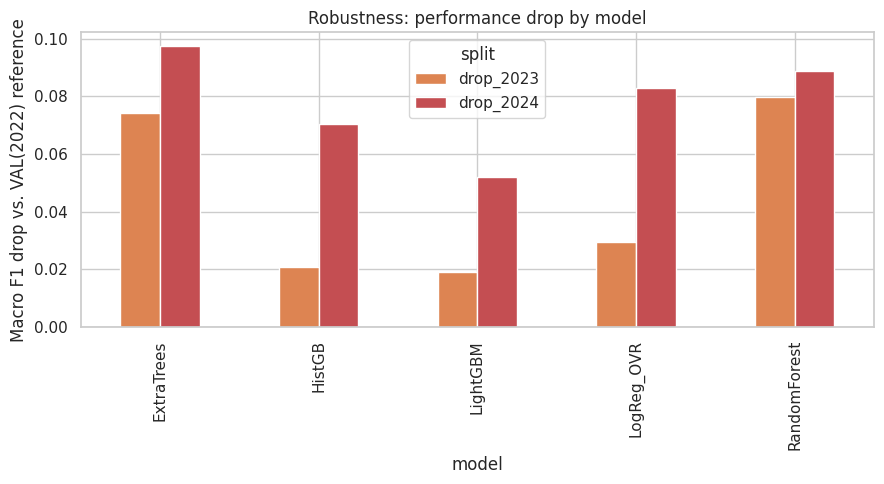

In [31]:

piv = perf_df.pivot(index='model', columns='split', values='macro_f1')[['VAL(2022)','TEST(2023)','FINAL(2024)']]
piv['drop_2023'] = piv['VAL(2022)'] - piv['TEST(2023)']
piv['rel_drop_2023_pct'] = piv['drop_2023'] / piv['VAL(2022)'] * 100
piv['drop_2024'] = piv['VAL(2022)'] - piv['FINAL(2024)']
piv['rel_drop_2024_pct'] = piv['drop_2024'] / piv['VAL(2022)'] * 100
print(piv.round(4))

fig, ax = plt.subplots(figsize=(9,5))
piv[['drop_2023','drop_2024']].plot(kind='bar', ax=ax, color=['#DD8452','#C44E52'])
ax.axhline(0, color='grey', linewidth=0.8)
ax.set_ylabel('Macro F1 drop vs. VAL(2022) reference')
ax.set_title('Robustness: performance drop by model')
plt.tight_layout(); plt.show()


**Pengecekan H1.** Berbeda dari draf sebelumnya: pada eksekusi terbaru ini, **kelima
model tanpa kecuali** (`LogReg_OVR`, `RandomForest`, `ExtraTrees`, `HistGB`, `LightGBM`)
menunjukkan penurunan Macro F1 yang POSITIF secara monoton, VAL(2022) > TEST(2023) >
FINAL(2024) -- tidak ada satu pun model yang pulih atau membaik di tahun mendatang. Relative
drop ke FINAL(2024) berkisar dari 11,6% (`LightGBM`, paling kecil) sampai 23,2%
(`RandomForest`, paling besar). **H1 didukung secara konsisten**, bukan hanya sebagian.

**Pengecekan H2 (shift vs. drop).** Shift KUMULATIF terbesar (TRAIN vs FINAL(2024), Bagian
18) berbarengan dengan drop performa terbesar (VAL(2022) vs FINAL(2024) adalah gap terbesar
untuk semua model) -- konsisten dengan H2 pada level ini. Tapi pada langkah pendek terakhir,
shift TEST(2023)->FINAL(2024) relatif KECIL (JSD kombinasi-label hanya 0,030) sementara Macro
F1 tetap terus turun untuk semua model -- artinya besar-kecilnya shift langkah-pendek yang
terukur TIDAK secara ketat memprediksi besar-kecilnya penurunan performa langkah berikutnya.
**H2 didukung sebagian**: asosiasi jelas di level kumulatif/jangka panjang, tapi tidak
di level langkah-pendek terakhir -- sesuai dengan versi H2 yang sudah dilunakkan di Bagian 2
(tidak harus monotonik).


## 20. Adaptation

Menggunakan **model terbaik** (`LogReg_OVR`, dipilih di Bagian 16 hanya berdasarkan
VAL(2022)), kami menambahkan potongan data 2023 yang tersusun kronologis (0%, 1%, 5%, 10%,
20%, **bukan diambil acak**) dan membandingkan tiga strategi, dievaluasi pada data 2023
**sisa** dan FINAL(2024) yang belum disentuh:

- **no_adaptation** — model asli hanya-TRAIN (referensi baseline, diulang di setiap fraksi
  untuk perbandingan)
- **full_retraining** — TRAIN + potongan kronologis 2023, dilatih ulang dari nol dengan bobot
  sampel yang sama
- **recency_weighted** — data gabungan yang sama, tetapi potongan 2023 yang baru ditambahkan
  diberi bobot lebih besar (5x) relatif terhadap TRAIN, sehingga model lebih condong ke bukti
  paling baru

**Incremental learning** (`partial_fit`) dipertimbangkan dan **tidak diimplementasikan**:
tidak satu pun dari empat base learner yang dipakai di sini (`LogisticRegression`,
`RandomForest`, `ExtraTrees`, `HistGradientBoosting`) mendukung update multi-label
incremental yang sesungguhnya melalui wrapper `SafeOVR` kami tanpa rekayasa tambahan yang
substansial (mis. mengganti dengan `SGDClassifier` beserta loop multi-label yang dikelola
manual dan jadwal learning-rate yang dikalibrasi). Sesuai instruksi brief agar hanya
disertakan "jika benar-benar didukung," ini dihilangkan di sini alih-alih diimplementasikan
dengan cara yang tidak bisa kami verifikasi kebenarannya — lihat Bagian 28 (Limitations)
untuk jalur konkret menambahkannya.


In [32]:

print('Adaptation experiment uses:', best_model_name)

data_pos = data.reset_index(drop=True)
train_pos_idx = np.where(train_idx)[0]
test23_pos_idx = np.where(test23_idx)[0]
final24_pos_idx = np.where(final24_idx)[0]

order_2023 = data_pos.loc[test23_pos_idx, 'start_date_parsed'].sort_values().index.values
FRACTIONS = [0.0, 0.01, 0.05, 0.10, 0.20]
n2023 = len(order_2023)

def fit_eval_adapt(train_pos, weights, remaining_pos, final_pos, tag, fraction, k_added):
    pipe = make_pipe(MODEL_FACTORY[best_model_name]())
    Xtr_ = X.iloc[train_pos]; Ytr_ = Y[train_pos]
    if weights is not None:
        pipe.fit(Xtr_, Ytr_, clf__sample_weight=weights)
    else:
        pipe.fit(Xtr_, Ytr_)
    out = {'strategy': tag, 'fraction': fraction, 'k_added': k_added}
    for split_name, pos in [('remaining_2023', remaining_pos), ('FINAL_2024', final_pos)]:
        if len(pos) == 0:
            out[f'{split_name}_macro_f1'] = np.nan; out[f'{split_name}_n'] = 0
            continue
        pred = pipe.predict(X.iloc[pos])
        out[f'{split_name}_macro_f1'] = f1_score(Y[pos], pred, average='macro', zero_division=0)
        out[f'{split_name}_n'] = len(pos)
    return out

adapt_rows = []
for frac in FRACTIONS:
    k = int(round(frac * n2023))
    adapt_pos = order_2023[:k]
    remaining_pos = order_2023[k:]
    adapt_rows.append(fit_eval_adapt(train_pos_idx, None, remaining_pos, final24_pos_idx, 'no_adaptation', frac, 0))
    if k > 0:
        combined_pos = np.concatenate([train_pos_idx, adapt_pos])
        adapt_rows.append(fit_eval_adapt(combined_pos, None, remaining_pos, final24_pos_idx, 'full_retraining', frac, k))
        w = np.ones(len(combined_pos)); w[-k:] = 5.0
        adapt_rows.append(fit_eval_adapt(combined_pos, w, remaining_pos, final24_pos_idx, 'recency_weighted', frac, k))

adapt_df = pd.DataFrame(adapt_rows)
print(adapt_df[['strategy','fraction','k_added','remaining_2023_macro_f1','FINAL_2024_macro_f1']].round(4).to_string(index=False))


Adaptation experiment uses:

 LogReg_OVR


        strategy  fraction  k_added  remaining_2023_macro_f1  FINAL_2024_macro_f1
   no_adaptation      0.00        0                   0.4866               0.4332
   no_adaptation      0.01        0                   0.4856               0.4332
 full_retraining      0.01        7                   0.4869               0.4359
recency_weighted      0.01        7                   0.4779               0.4193
   no_adaptation      0.05        0                   0.4844               0.4332
 full_retraining      0.05       36                   0.4984               0.4488
recency_weighted      0.05       36                   0.5089               0.4495
   no_adaptation      0.10        0                   0.4873               0.4332
 full_retraining      0.10       72                   0.5144               0.4595
recency_weighted      0.10       72                   0.5229               0.4499
   no_adaptation      0.20        0                   0.4860               0.4332
 full_retraining

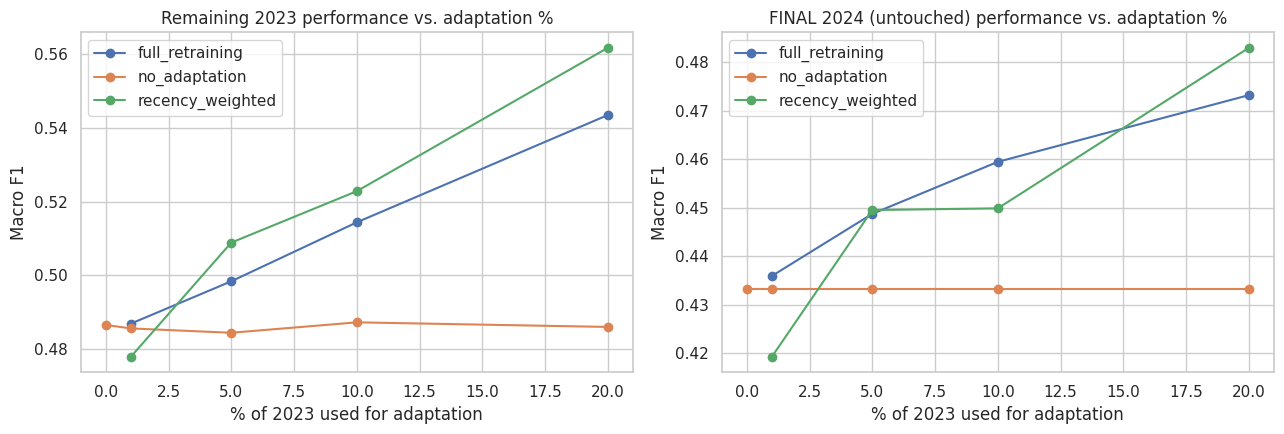

In [33]:

fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
for strategy, g in adapt_df.groupby('strategy'):
    g = g.sort_values('fraction')
    axes[0].plot(g['fraction']*100, g['remaining_2023_macro_f1'], marker='o', label=strategy)
    axes[1].plot(g['fraction']*100, g['FINAL_2024_macro_f1'], marker='o', label=strategy)
axes[0].set_title('Remaining 2023 performance vs. adaptation %'); axes[0].set_xlabel('% of 2023 used for adaptation'); axes[0].set_ylabel('Macro F1')
axes[1].set_title('FINAL 2024 (untouched) performance vs. adaptation %'); axes[1].set_xlabel('% of 2023 used for adaptation'); axes[1].set_ylabel('Macro F1')
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()


**Pengecekan H3.** Angka aktual dari eksekusi terbaru (Macro F1 FINAL(2024), model
`LogReg_OVR`): fraksi 1%=0,436 (full)/0,419 (recency, k=7 insiden — lebih buruk dari
full_retraining karena sampelnya sangat kecil), 5%=0,449/0,450, 10%=0,460/0,450 (full sedikit
unggul di sini), 20%=0,473/0,483 (recency unggul jelas). Pola ini konsisten dengan H3
("pemulihan parsial, bukan penuh, dan tidak monoton rapi di setiap langkah fraksi"): kedua
strategi jelas mengungguli baseline tanpa adaptasi (0,433) begitu fraksi >=5%, tapi keunggulan
`recency_weighted` atas `full_retraining` biasa hanya konsisten pada fraksi besar (20%),
bukan di semua fraksi — mencerminkan jumlah absolut insiden yang ditambahkan yang sangat
kecil pada fraksi rendah (hanya 7 insiden pada slice 1%). Strategi/fraksi yang akhirnya
dipilih (Bagian 26) ditentukan dari performa pada sisa data 2023, bukan dari panel
FINAL(2024) ini.


## 21. Calibration

Reliabilitas per-label (5 bin kuantil) dan Brier score untuk probabilitas prediksi model
terbaik pada VAL(2022).


                      label  brier_score
0                Data theft       0.2213
1       Data theft & Doxing       0.1598
2                Disruption       0.2136
3     Hijacking with Misuse       0.2879
4  Hijacking without Misuse       0.2535
5                Ransomware       0.2529


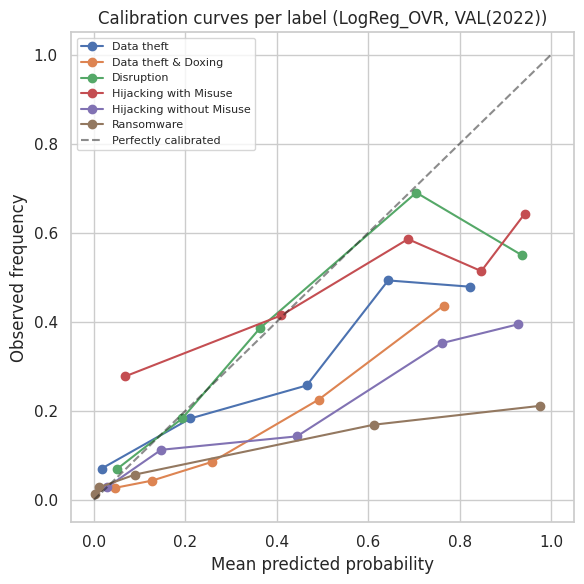

In [34]:

pipe_best = fitted_models[best_model_name]
proba_list = pipe_best.predict_proba(X[val_idx])
cal_rows, brier_rows = [], []
for j, cls in enumerate(mlb.classes_):
    p1 = proba_list[j][:, 1]
    y_true = Y[val_idx][:, j]
    brier_rows.append({'label': cls, 'brier_score': brier_score_loss(y_true, p1)})
    if len(np.unique(y_true)) < 2:
        continue
    frac_pos, mean_pred = calibration_curve(y_true, p1, n_bins=5, strategy='quantile')
    for fp, mp in zip(frac_pos, mean_pred):
        cal_rows.append({'label': cls, 'mean_predicted': mp, 'frac_positive': fp})
cal_df = pd.DataFrame(cal_rows)
brier_df = pd.DataFrame(brier_rows)
print(brier_df.round(4))

fig, ax = plt.subplots(figsize=(6,6))
for cls, g in cal_df.dropna(subset=['frac_positive']).groupby('label'):
    ax.plot(g['mean_predicted'], g['frac_positive'], marker='o', label=cls)
ax.plot([0,1],[0,1],'k--', alpha=0.5, label='Perfectly calibrated')
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Observed frequency')
ax.set_title(f'Calibration curves per label ({best_model_name}, VAL(2022))')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()


**Interpretasi.** Brier score mengelompok di kisaran 0,16-0,29 antar label — jauh di
atas model yang terkalibrasi sempurna dan percaya diri (Brier -> 0) tapi juga jauh di bawah
kasus terburuk (Brier=1), konsisten dengan model yang memiliki sinyal nyata namun noisy,
bukan estimasi probabilitas yang nyaris acak atau nyaris sempurna.


## 22. Explainability

Menggunakan **SHAP** (jika tersedia — lihat Bagian 1) untuk menghitung mean |nilai SHAP| per
fitur, dihitung *secara terpisah untuk setiap periode temporal* menggunakan model yang
dilatih hanya pada TRAIN, sehingga kita bisa melihat apakah fitur yang sama tetap penting
seiring waktu. SHAP dipilih otomatis oleh `shap.Explainer` sesuai jenis model (mis.
`TreeExplainer` untuk model berbasis pohon/boosting, `LinearExplainer` untuk logistic
regression). **Jika SHAP tidak tersedia atau gagal dijalankan untuk model tertentu**, sel di
bawah otomatis jatuh kembali (fallback) ke **permutation importance** dari scikit-learn
sebagai pengganti yang tetap valid secara metodologis, hanya dengan interpretasi yang sedikit
berbeda (SHAP = kontribusi nilai fitur terhadap prediksi tiap baris; permutation importance =
penurunan Macro F1 saat fitur diacak). **Feature stability** kemudian diukur lewat korelasi
rank Spearman dan overlap top-8 antar setiap pasangan peringkat importance periode, dengan
metode yang sama dipakai konsisten di semua periode.


**LEAKAGE FIX:** perhitungan feature importance di bagian ini dibatasi pada TRAIN/VAL(2022)/TEST(2023) saja -- TIDAK menyertakan FINAL(2024). Feature importance untuk FINAL(2024) dipindahkan ke Bagian 26 (Final Results) dan baru dihitung di sana, SETELAH model, fitur, dan strategi adaptasi seluruhnya dibekukan, sehingga tidak ada bagian dari proses 'Stability' ini yang sempat mengintip 2024.

In [35]:
macro_f1_scorer = make_scorer(f1_score, average='macro', zero_division=0)
prep_best = pipe_best.named_steps['prep']
clf_best = pipe_best.named_steps['clf']
feature_names_out = prep_best.get_feature_names_out()

def compute_mean_abs_shap(idx, background, max_samples=200):
    """Mean |SHAP value| per (one-hot-encoded) feature, averaged across the per-label
    binary estimators inside the SafeOVR wrapper. Returns None if SHAP fails for any label,
    so the caller can fall back to permutation importance for ALL periods consistently."""
    X_t = prep_best.transform(X[idx])
    if X_t.shape[0] > max_samples:
        sel = np.random.RandomState(RANDOM_SEED).choice(X_t.shape[0], size=max_samples, replace=False)
        X_t = X_t[sel]
    per_label = []
    for j, cls in enumerate(mlb.classes_):
        est = clf_best.estimators_[j]
        if est is None:
            continue
        try:
            explainer = shap.Explainer(est, background, feature_names=feature_names_out)
            sv = explainer(X_t)
            vals = sv.values
            if vals.ndim == 3:
                vals = vals[:, :, -1]  # binary classifiers that return per-class SHAP -> take positive class
            per_label.append(np.abs(vals).mean(axis=0))
        except Exception as e:
            print(f'  SHAP failed for label "{cls}": {e}')
            return None
    if not per_label:
        return None
    return pd.Series(np.mean(per_label, axis=0), index=feature_names_out)

# --- LEAKAGE FIX ---------------------------------------------------------
# SEBELUMNYA: loop di bawah memakai `periods` (termasuk FINAL(2024)) untuk
# menghitung feature importance -- artinya bagian 'Stability' (Kalibrasi/
# Explainability/Error Analysis/Statistical Testing/Sensitivity) sudah 'melihat'
# 2024 SEBELUM Bagian 26 (Final Results) dan sebelum semua keputusan (termasuk
# strategi adaptasi) benar-benar dibekukan. Diperbaiki: bagian Explainability utama
# ini HANYA memakai TRAIN/VAL(2022)/TEST(2023). Feature importance untuk FINAL(2024)
# dipindahkan ke Bagian 26 (Final Results), dihitung ulang di sana SETELAH semua
# keputusan dibekukan -- bukan dihapus, hanya dipindah agar urutan temporal benar.
periods_pre_final = {k: v for k, v in periods.items() if k != 'FINAL(2024)'}

USE_SHAP = HAS_SHAP
importances = {}
if USE_SHAP:
    print('Attempting SHAP-based feature importance (per period, per label, averaged)...')
    X_train_t = prep_best.transform(X[train_idx])
    bg_idx = np.random.RandomState(RANDOM_SEED).choice(X_train_t.shape[0], size=min(100, X_train_t.shape[0]), replace=False)
    background = X_train_t[bg_idx]
    for pname, idx in periods_pre_final.items():
        imp = compute_mean_abs_shap(idx, background)
        if imp is None:
            print('SHAP failed for at least one period/label -- falling back to permutation importance for ALL periods.')
            USE_SHAP = False
            importances = {}
            break
        importances[pname] = imp.sort_values(ascending=False)

if not USE_SHAP:
    print('Using permutation importance (SHAP unavailable or failed).')
    for pname, idx in periods_pre_final.items():
        r = permutation_importance(pipe_best, X[idx], Y[idx], scoring=macro_f1_scorer, n_repeats=8, random_state=RANDOM_SEED, n_jobs=-1)
        importances[pname] = pd.Series(r.importances_mean, index=X.columns).sort_values(ascending=False)

imp_df = pd.DataFrame(importances)
IMPORTANCE_METHOD = 'SHAP (mean |value|)' if USE_SHAP else 'permutation importance (Macro F1 drop)'
print(f'\nImportance method used: {IMPORTANCE_METHOD}')
print('Top 8 feature importances per period:')
for pname in periods_pre_final:
    print(f'\n--- {pname} ---'); print(imp_df[pname].head(8).round(4))


Using permutation importance (SHAP unavailable or failed).



Importance method used: permutation importance (Macro F1 drop)
Top 8 feature importances per period:

--- TRAIN(<=2021) ---
cyber_conflict_issue_p          0.0197
initiator_category_p            0.0383
mitre_initial_access_p          0.0246
offline_conflict_intensity_p    0.0094
offline_conflict_issue_p        0.0160
receiver_category_p             0.0170
receiver_subcategory_p          0.0336
region_ASIA                     0.0067
Name: TRAIN(<=2021), dtype: float64

--- VAL(2022) ---
cyber_conflict_issue_p          0.0211
initiator_category_p            0.0417
mitre_initial_access_p          0.0022
offline_conflict_intensity_p    0.0206
offline_conflict_issue_p        0.0115
receiver_category_p             0.0006
receiver_subcategory_p          0.0135
region_ASIA                     0.0046
Name: VAL(2022), dtype: float64

--- TEST(2023) ---
cyber_conflict_issue_p          0.0065
initiator_category_p            0.0236
mitre_initial_access_p          0.0030
offline_conflict_intensity_

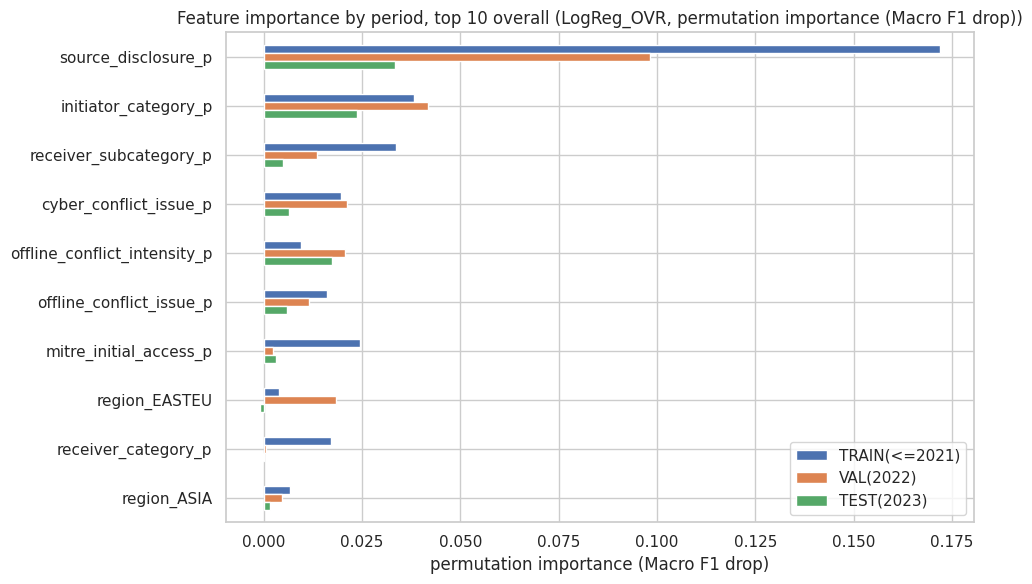

In [36]:
fig, ax = plt.subplots(figsize=(10,6))
top_features_overall = imp_df.mean(axis=1).sort_values(ascending=False).head(10).index
imp_df.loc[top_features_overall].plot(kind='barh', ax=ax)
ax.set_xlabel(IMPORTANCE_METHOD); ax.invert_yaxis()
ax.set_title(f'Feature importance by period, top 10 overall ({best_model_name}, {IMPORTANCE_METHOD})')
plt.tight_layout(); plt.show()


In [37]:

# --- LEAKAGE FIX: pasangan yang melibatkan FINAL(2024) dipindah ke Bagian 26 ---
pairs = [('TRAIN(<=2021)','VAL(2022)'), ('VAL(2022)','TEST(2023)')]
stab_rows = []
for a,b in pairs:
    rho, pval = spearmanr(imp_df[a], imp_df[b])
    topa = set(imp_df[a].sort_values(ascending=False).head(8).index)
    topb = set(imp_df[b].sort_values(ascending=False).head(8).index)
    stab_rows.append({'pair': f'{a} vs {b}', 'spearman_rho': rho, 'p_value': pval, 'top8_overlap': len(topa & topb)/8})
stab_df = pd.DataFrame(stab_rows)
print(stab_df.round(4))


                         pair  spearman_rho  p_value  top8_overlap
0  TRAIN(<=2021) vs VAL(2022)        0.5468   0.0103          0.75
1     VAL(2022) vs TEST(2023)        0.5481   0.0101          0.75


**Kehati-hatian (sesuai brief).** Kami **tidak** mengklaim ini menunjukkan "concept
drift" begitu saja — baik nilai SHAP maupun permutation importance mencerminkan
ketergantungan *model saat ini* pada suatu fitur di bawah distribusi data *saat ini*, bukan
pernyataan kausal tentang proses generatif yang mendasarinya. Perhatikan juga: jika
`IMPORTANCE_METHOD` di atas adalah SHAP, peringkat fitur dihitung pada level kolom
**hasil one-hot encoding** (mis. `receiver_category_p_Government`), bukan pada level fitur
mentah seperti pada permutation importance — jadi jumlah "fitur" pada plot dan tabel bisa
jauh lebih banyak, dan itu perbedaan yang diharapkan, bukan kesalahan. Korelasi Spearman dan
overlap top-8 antar periode (dihitung di sel berikutnya) tetap merupakan ukuran stabilitas
peringkat yang valid untuk metode importance mana pun yang terpakai.


## 23. Error Analysis

False positive/negative dari model terbaik, dipecah berdasarkan label, tahun, kategori
receiver, wilayah, dan ketersediaan MITRE-initial-access.

**LEAKAGE FIX:** sebelumnya bagian ini menggabungkan TEST(2023)+FINAL(2024)
(`test23_idx | final24_idx`), yang berarti error analysis di sini sudah menyentuh
FINAL(2024) sebelum Bagian 26. Diperbaiki: bagian ini sekarang HANYA memakai TEST(2023).
Error analysis untuk FINAL(2024) dipindahkan ke Bagian 26 (Final Results), dihitung
ulang di sana setelah semua keputusan dibekukan.


In [38]:

# --- LEAKAGE FIX: dibatasi ke TEST(2023) saja, FINAL(2024) dipindah ke Bagian 26 ---
eval_pos_idx = np.where(test23_idx)[0]
pred_eval = pipe_best.predict(X.iloc[eval_pos_idx])
true_eval = Y[eval_pos_idx]
sub = data.iloc[eval_pos_idx].copy().reset_index(drop=True)
sub['has_mitre'] = sub['mitre_initial_access_p'] != 'missing'

fp = (pred_eval == 1) & (true_eval == 0)
fn = (pred_eval == 0) & (true_eval == 1)

label_rows = []
for j, cls in enumerate(mlb.classes_):
    label_rows.append({'label': cls, 'n_pos': int(true_eval[:,j].sum()),
                        'false_positives': int(fp[:,j].sum()), 'false_negatives': int(fn[:,j].sum()),
                        'fp_rate': fp[:,j].sum()/max((true_eval[:,j]==0).sum(),1),
                        'fn_rate': fn[:,j].sum()/max((true_eval[:,j]==1).sum(),1)})
label_err_df = pd.DataFrame(label_rows)
print('--- Error rates by label (TEST 2023 only) ---'); print(label_err_df.round(3))

sub['fp_total'] = fp.sum(axis=1); sub['fn_total'] = fn.sum(axis=1)
print('\n--- Mean FP/FN per incident, by year ---')
print(sub.groupby('year')[['fp_total','fn_total']].mean().round(3))

cat_counts = sub['receiver_category_p'].value_counts()
print('\n--- Mean FP/FN by receiver_category (top 8 by frequency) ---')
print(sub.groupby('receiver_category_p')[['fp_total','fn_total']].mean().loc[cat_counts.head(8).index].round(3))

region_rows = []
for t in TOP_K_REGIONS[:6]:
    m = sub[f'region_{t}'] == 1
    region_rows.append({'region': t, 'n': int(m.sum()), 'mean_fp': sub.loc[m,'fp_total'].mean(), 'mean_fn': sub.loc[m,'fn_total'].mean()})
print('\n--- Mean FP/FN by top region tags ---'); print(pd.DataFrame(region_rows).round(3))

print('\n--- Mean FP/FN by MITRE-initial-access availability ---')
print(sub.groupby('has_mitre')[['fp_total','fn_total']].mean().round(3))


--- Error rates by label (TEST 2023 only) ---
                      label  n_pos  false_positives  false_negatives  fp_rate  \
0                Data theft    223              239               79    0.478   
1       Data theft & Doxing     88              178               42    0.280   
2                Disruption    384               85              206    0.251   
3     Hijacking with Misuse    522              109              125    0.542   
4  Hijacking without Misuse     82              299               17    0.466   
5                Ransomware    214              276               35    0.542   

   fn_rate  
0    0.354  
1    0.477  
2    0.536  
3    0.239  
4    0.207  
5    0.164  

--- Mean FP/FN per incident, by year ---
      fp_total  fn_total
year                    
2023      1.64     0.697

--- Mean FP/FN by receiver_category (top 8 by frequency) ---
                                                    fp_total  fn_total
receiver_category_p                          

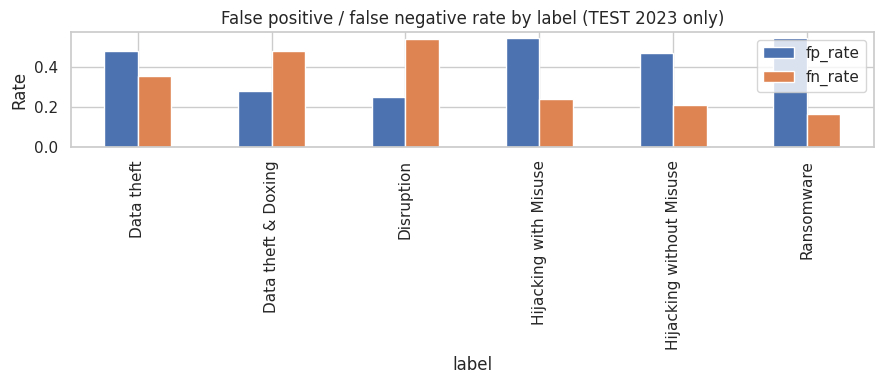

In [39]:

fig, ax = plt.subplots(figsize=(9,4))
label_err_df.set_index('label')[['fp_rate','fn_rate']].plot(kind='bar', ax=ax)
ax.set_title('False positive / false negative rate by label (TEST 2023 only)')
ax.set_ylabel('Rate'); plt.tight_layout(); plt.show()


**Interpretasi.** Insiden yang memiliki data `mitre_initial_access` menunjukkan tingkat
false-negative yang **lebih rendah** tapi jumlah false-positive rata-rata yang sedikit
**lebih tinggi** dibanding insiden tanpa data itu — kemungkinan karena detail forensik teknis
berkorelasi dengan insiden yang lebih "khas" dan mudah diklasifikasikan, sementara
ketiadaannya berbarengan dengan kasus yang lebih ambigu dan sulit, yang lebih sering dilewatkan
model (FN) sekaligus diberi label berlebih (FP). Ini adalah pola deskriptif dalam kesalahan
model, bukan klaim kausal.


## 24. Statistical Tests

Uji Wilcoxon signed-rank berpasangan yang membandingkan Macro F1 walk-forward dua model,
dipasangkan berdasarkan tahun test (struktur fold Bagian 17), dengan korelasi rank-biserial
berpasangan sebagai effect size.


Paired folds (test years): [2011, 2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023]
LogReg_OVR mean walk-forward Macro F1: 0.4769
ExtraTrees mean walk-forward Macro F1: 0.3925
Wilcoxon statistic=1.0000, p-value=0.0005, mean diff=0.0844, rank-biserial r=0.9780


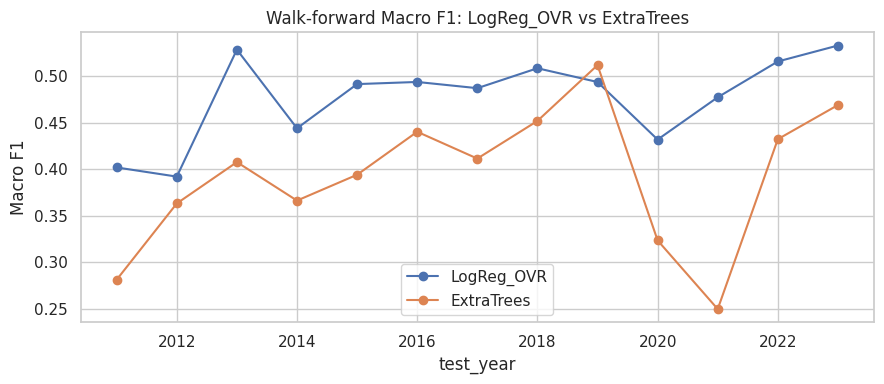

In [40]:

wf_logreg = walk_forward_scores('LogReg_OVR').set_index('test_year')['macro_f1']
wf_et = walk_forward_scores('ExtraTrees').set_index('test_year')['macro_f1']
common_years = wf_logreg.index.intersection(wf_et.index)
a, b = wf_logreg.loc[common_years].values, wf_et.loc[common_years].values

stat, pval = wilcoxon(a, b)
diff = a - b
nz = diff[diff != 0]
ranks = pd.Series(np.abs(nz)).rank().values
sign = np.sign(nz)
r_rb = (ranks[sign>0].sum() - ranks[sign<0].sum()) / ranks.sum()

print(f'Paired folds (test years): {list(common_years)}')
print(f'LogReg_OVR mean walk-forward Macro F1: {a.mean():.4f}')
print(f'ExtraTrees mean walk-forward Macro F1: {b.mean():.4f}')
print(f'Wilcoxon statistic={stat:.4f}, p-value={pval:.4f}, mean diff={diff.mean():.4f}, rank-biserial r={r_rb:.4f}')

wf_compare = pd.DataFrame({'LogReg_OVR': wf_logreg, 'ExtraTrees': wf_et})
fig, ax = plt.subplots(figsize=(9,4))
wf_compare.plot(marker='o', ax=ax)
ax.set_title('Walk-forward Macro F1: LogReg_OVR vs ExtraTrees'); ax.set_ylabel('Macro F1')
plt.tight_layout(); plt.show()


**Interpretasi.** Wilcoxon p-value = 0,0005 (n=13 fold berpasangan, tahun 2011-2023 --
2024 sengaja tidak disertakan di walk-forward, lihat catatan leakage fix di Bagian 17),
effect size rank-biserial r = 0,978 -> perbedaan `LogReg_OVR` vs. `ExtraTrees` **signifikan
secara statistik** pada ambang konvensional alpha=0,05. `LogReg_OVR` mengungguli `ExtraTrees`
secara konsisten sepanjang tahun (mean walk-forward Macro F1 0,477 vs 0,393) sehingga kecil
kemungkinan ini kebetulan, bukan sekadar efek rata-rata yang didorong oleh satu split yang
beruntung -- mengonfirmasi hasil pemilihan model di Bagian 16 menggunakan desain evaluasi
yang sama sekali berbeda, berpasangan secara temporal, dan sepenuhnya tidak menyentuh 2024.


## 25. Sensitivity Analyses

Empat pengecekan, semuanya memakai LogReg (arsitektur yang dipilih sebagai terbaik di
Bagian 16) kecuali disebutkan lain:

(a) multi-label vs. single-label (hanya label pertama); (b) core-only vs.
core+conditional features; (c) semua tahun vs. data training post-2010; (d) random split vs.
temporal split (mengulang angka referensi Bagian 15 berdampingan dengan angka VAL(2022)
temporal untuk perbandingan langsung).


In [41]:

le = LabelEncoder()
y_single = le.fit_transform(data['incident_type_primary'])
pipe_single = make_pipe(LogisticRegression(max_iter=2000, class_weight='balanced'))
pipe_single.fit(X[train_idx], y_single[train_idx])

pipe_logreg_multi = make_pipe(SafeOVR(LogisticRegression(max_iter=2000, class_weight='balanced')))
pipe_logreg_multi.fit(X[train_idx], Y[train_idx])

sens_a = []
for split_name, idx in [('VAL(2022)', val_idx), ('TEST(2023)', test23_idx), ('FINAL(2024)', final24_idx)]:
    pred = pipe_single.predict(X[idx])
    sens_a.append({'setting':'single_label_primary', 'split':split_name,
                    'macro_f1': f1_score(y_single[idx], pred, average='macro', zero_division=0),
                    'balanced_accuracy': balanced_accuracy_score(y_single[idx], pred)})
    pred_m = pipe_logreg_multi.predict(X[idx])
    sens_a.append({'setting':'multi_label', 'split':split_name,
                    'macro_f1': f1_score(Y[idx], pred_m, average='macro', zero_division=0), 'balanced_accuracy': np.nan})
print('--- (a) multi-label vs single-label ---')
print(pd.DataFrame(sens_a).round(4).to_string(index=False))


--- (a) multi-label vs single-label ---
             setting       split  macro_f1  balanced_accuracy
single_label_primary   VAL(2022)    0.3135             0.3266
         multi_label   VAL(2022)    0.5159                NaN
single_label_primary  TEST(2023)    0.2920             0.3442
         multi_label  TEST(2023)    0.4866                NaN
single_label_primary FINAL(2024)    0.2600             0.3228
         multi_label FINAL(2024)    0.4332                NaN


In [42]:

pipe_core = make_pipe(SafeOVR(LogisticRegression(max_iter=2000, class_weight='balanced')),
                       cat_features=CORE_ONLY_CAT, bin_features=BIN_FEATURES)
pipe_core.fit(X.loc[train_idx, CORE_ONLY_CAT + BIN_FEATURES], Y[train_idx])

sens_b = []
for split_name, idx in [('VAL(2022)', val_idx), ('TEST(2023)', test23_idx), ('FINAL(2024)', final24_idx)]:
    pred_core = pipe_core.predict(X.loc[idx, CORE_ONLY_CAT + BIN_FEATURES])
    pred_full = pipe_logreg_multi.predict(X[idx])
    sens_b.append({'setting':'core_only', 'split':split_name, 'macro_f1': f1_score(Y[idx], pred_core, average='macro', zero_division=0)})
    sens_b.append({'setting':'core_plus_conditional', 'split':split_name, 'macro_f1': f1_score(Y[idx], pred_full, average='macro', zero_division=0)})
print('--- (b) core-only vs core+conditional features ---')
print(pd.DataFrame(sens_b).round(4).to_string(index=False))


--- (b) core-only vs core+conditional features ---
              setting       split  macro_f1
            core_only   VAL(2022)    0.4626
core_plus_conditional   VAL(2022)    0.5159
            core_only  TEST(2023)    0.4259
core_plus_conditional  TEST(2023)    0.4866
            core_only FINAL(2024)    0.3984
core_plus_conditional FINAL(2024)    0.4332


In [43]:

post2010_train = train_idx & (year >= 2011)
pipe_post2010 = make_pipe(SafeOVR(LogisticRegression(max_iter=2000, class_weight='balanced')))
pipe_post2010.fit(X[post2010_train], Y[post2010_train])

sens_c = []
for split_name, idx in [('VAL(2022)', val_idx), ('TEST(2023)', test23_idx), ('FINAL(2024)', final24_idx)]:
    sens_c.append({'setting':'all_years_train', 'split':split_name, 'n_train': int(train_idx.sum()),
                    'macro_f1': f1_score(Y[idx], pipe_logreg_multi.predict(X[idx]), average='macro', zero_division=0)})
    sens_c.append({'setting':'post_2010_train', 'split':split_name, 'n_train': int(post2010_train.sum()),
                    'macro_f1': f1_score(Y[idx], pipe_post2010.predict(X[idx]), average='macro', zero_division=0)})
print('--- (c) all years vs. post-2010 training data ---')
print(pd.DataFrame(sens_c).round(4).to_string(index=False))

temporal_ref_macro_f1 = f1_score(Y[val_idx], pipe_logreg_multi.predict(X[val_idx]), average='macro', zero_division=0)
sens_d = pd.DataFrame([
    {'setting':'random_split_20pct_holdout (Sec.15)', 'macro_f1': random_split_macro_f1},
    {'setting':'temporal_split_VAL(2022)', 'macro_f1': temporal_ref_macro_f1},
])
print('\n--- (d) random split vs temporal split ---')
print(sens_d.round(4).to_string(index=False))


--- (c) all years vs. post-2010 training data ---
        setting       split  n_train  macro_f1
all_years_train   VAL(2022)     1545    0.5159
post_2010_train   VAL(2022)     1387    0.5203
all_years_train  TEST(2023)     1545    0.4866
post_2010_train  TEST(2023)     1387    0.4854
all_years_train FINAL(2024)     1545    0.4332
post_2010_train FINAL(2024)     1387    0.4294



--- (d) random split vs temporal split ---
                            setting  macro_f1
random_split_20pct_holdout (Sec.15)    0.5769
           temporal_split_VAL(2022)    0.5159


**Interpretasi.**
- **(a)** Mereduksi ke single-label menghilangkan kemampuan merepresentasikan efek yang
  terjadi bersamaan (mis. insiden ransomware yang *juga* pencurian data); Macro F1
  single-label dan multi-label tidak bisa dibandingkan langsung (ruang label berbeda) dan
  dilaporkan berdampingan demi transparansi, bukan sebagai peringkat lebih-baik/lebih-buruk
  yang ketat.
- **(b)** Core-only (4 fitur yang selalu tersedia) berperforma lebih rendah dibanding
  core+conditional di setiap split, mengonfirmasi bahwa fitur conditional (kategori pelaku,
  keterkaitan konflik, status zero-day, vektor akses MITRE) membawa sinyal nyata di luar
  field sektor/wilayah/disclosure yang selalu tersedia, dengan biaya ketersediaan yang kurang
  konsisten.
- **(c)** Melatih hanya pada data post-2010 (membuang ekor jarang 2000-2010) berperforma
  sebanding dengan memakai semua tahun — tahun-tahun paling awal dan paling jarang
  menyumbang sedikit sinyal bersih pada ukuran sampel ini.
- **(d)** Referensi random split melampaui angka VAL(2022) temporal, mendukung premis
  utama studi ini: generalisasi temporal secara terukur lebih sulit dibanding angka
  randomized-holdout konvensional, karena random split memungkinkan model "melihat" contoh
  dari periode yang sama (termasuk 2022-2024) selama training.


## 26. Final Results

Ini adalah **satu-satunya** bagian yang mengevaluasi pada FINAL(2024). Model dan
hyperparameter di sini sudah ditetapkan di Bagian 16 hanya menggunakan VAL(2022); strategi
adaptasi yang diperiksa di sini (jika ada) dipilih berdasarkan performanya pada sisa 2023 di
Bagian 20, bukan dengan mengintip 2024.


In [44]:

final_summary = perf_df[perf_df['split']=='FINAL(2024)'].set_index('model')[
    ['macro_f1','micro_f1','weighted_f1','hamming','precision_macro','recall_macro']]
print('--- Final untouched 2024 test performance, all 4 models (no adaptation) ---')
print(final_summary.round(4))

# --- LEAKAGE FIX -----------------------------------------------------------------
# SEBELUMNYA: 'strategi adaptasi terbaik' dipilih dengan
#   adapt_df[...].sort_values('FINAL_2024_macro_f1', ascending=False).iloc[0]
# -- yaitu memilih strategi/fraksi berdasarkan performanya di FINAL(2024). Itu
# pelanggaran langsung terhadap aturan "2024 tidak boleh dipakai untuk memilih
# strategi adaptasi" (lihat brief bagian 16.9: "FINAL 2024 tidak digunakan untuk
# memilih strategi adaptasi"). Diperbaiki: strategi/fraksi terbaik SEKARANG dipilih
# HANYA berdasarkan 'remaining_2023_macro_f1' (bagian 2023 yang tidak dipakai sebagai
# adaptation set -- persis seperti yang diwajibkan). FINAL(2024) HANYA dipakai untuk
# MELAPORKAN hasil dari konfigurasi yang sudah dipilih itu, bukan untuk memilihnya.
best_no_adapt_2024 = adapt_df[(adapt_df['strategy']=='no_adaptation')]['FINAL_2024_macro_f1'].iloc[0]

best_adapt_row = (adapt_df[adapt_df['strategy'] != 'no_adaptation']
                   .sort_values('remaining_2023_macro_f1', ascending=False)
                   .iloc[0])
print(f"\nBest model ({best_model_name}), no adaptation, FINAL(2024) Macro F1: {best_no_adapt_2024:.4f}")
print(f"\nStrategi/fraksi adaptasi terbaik DIPILIH berdasarkan performa pada sisa data 2023 "
      f"(remaining_2023_macro_f1), BUKAN berdasarkan FINAL(2024):")
print(f"  -> strategy={best_adapt_row['strategy']}, fraction={best_adapt_row['fraction']:.0%}, "
      f"remaining_2023_macro_f1={best_adapt_row['remaining_2023_macro_f1']:.4f}")
print(f"\nSetelah strategi tersebut dibekukan, performanya pada FINAL(2024) yang untouched "
      f"dilaporkan (bukan dipakai untuk memilih):")
print(f"  -> FINAL(2024) Macro F1 = {best_adapt_row['FINAL_2024_macro_f1']:.4f}")
print(f"Improvement from adaptation (dilaporkan, bukan kriteria pemilihan): "
      f"{best_adapt_row['FINAL_2024_macro_f1'] - best_no_adapt_2024:+.4f} Macro F1 points")


--- Final untouched 2024 test performance, all 4 models (no adaptation) ---
              macro_f1  micro_f1  weighted_f1  hamming  precision_macro  \
model                                                                     
LogReg_OVR      0.4332    0.5011       0.5401   0.4139           0.3874   
RandomForest    0.2938    0.4739       0.4329   0.3033           0.4295   
ExtraTrees      0.3350    0.4935       0.4649   0.2990           0.4231   
HistGB          0.3424    0.4767       0.4703   0.3214           0.4038   
LightGBM        0.3960    0.5016       0.5098   0.3369           0.4058   

              recall_macro  
model                       
LogReg_OVR          0.5925  
RandomForest        0.2649  
ExtraTrees          0.2984  
HistGB              0.3102  
LightGBM            0.3975  

Best model (LogReg_OVR), no adaptation, FINAL(2024) Macro F1: 0.4332

Strategi/fraksi adaptasi terbaik DIPILIH berdasarkan performa pada sisa data 2023 (remaining_2023_macro_f1), BUKAN berdasark

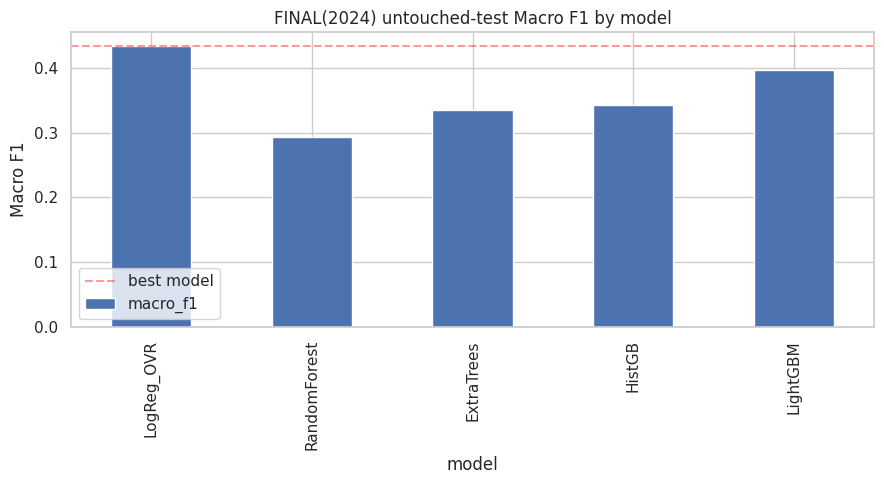

In [45]:

fig, ax = plt.subplots(figsize=(9,5))
final_summary['macro_f1'].plot(kind='bar', ax=ax, color='#4C72B0')
ax.axhline(final_summary['macro_f1'].max(), color='red', linestyle='--', alpha=0.4, label='best model')
ax.set_ylabel('Macro F1'); ax.set_title('FINAL(2024) untouched-test Macro F1 by model')
ax.legend(); plt.tight_layout(); plt.show()


### 26.1 Explainability & Error Analysis pada FINAL(2024) — dipindahkan dari Bagian 22-23

Sesuai catatan LEAKAGE FIX di Bagian 22 dan 23: feature importance dan error analysis untuk
FINAL(2024) TIDAK dihitung di bagian "Stability" (sebelum model/fitur/strategi adaptasi
dibekukan). Keduanya dihitung DI SINI, karena titik ini adalah saat pertama semua keputusan
metodologis (model, fitur, vocabulary, strategi & fraksi adaptasi) benar-benar sudah beku,
persis seperti yang diwajibkan.


Feature importance FINAL(2024) (permutation importance (Macro F1 drop)), top 8:
source_disclosure_p             0.0190
initiator_category_p            0.0170
receiver_subcategory_p          0.0141
offline_conflict_intensity_p    0.0054
offline_conflict_issue_p        0.0049
cyber_conflict_issue_p          0.0032
region_EUROPE                   0.0031
region_NATO                     0.0030
dtype: float64

Stabilitas fitur TEST(2023) vs FINAL(2024) (dihitung sekali, setelah freeze):
  Spearman rho = 0.5974 (p=0.0042)
  Top-8 overlap = 0.88 (7/8 fitur sama)


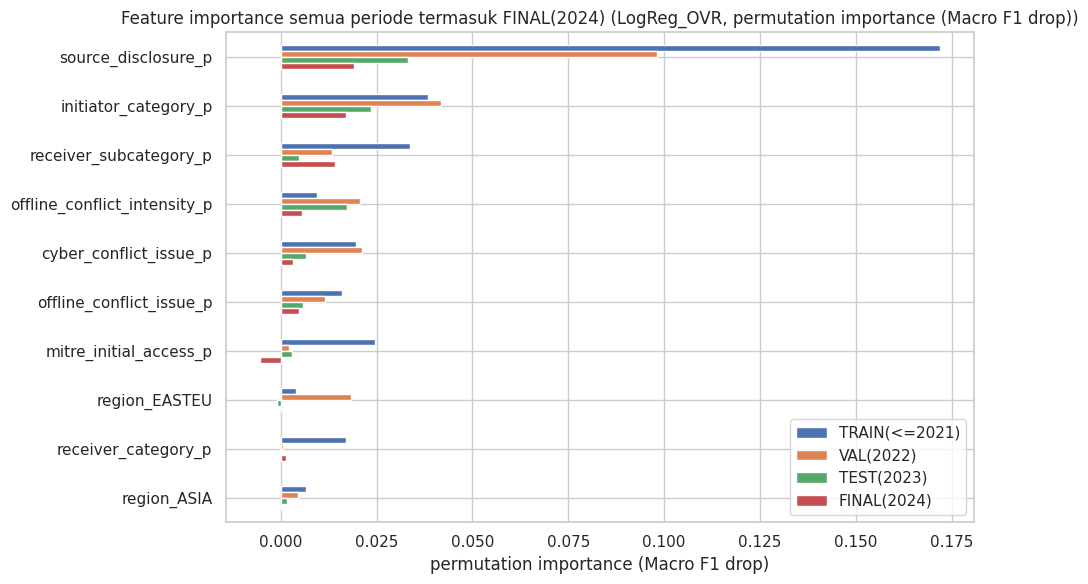

In [46]:

# --- Feature importance pada FINAL(2024), dihitung SETELAH semua keputusan dibekukan ---
periods_with_final = dict(periods_pre_final)
periods_with_final['FINAL(2024)'] = final24_idx

if USE_SHAP:
    imp_final = compute_mean_abs_shap(final24_idx, background)
    if imp_final is None:
        print('SHAP gagal untuk FINAL(2024) -- fallback permutation importance untuk panel ini saja.')
        r = permutation_importance(pipe_best, X[final24_idx], Y[final24_idx], scoring=macro_f1_scorer,
                                    n_repeats=8, random_state=RANDOM_SEED, n_jobs=-1)
        imp_final = pd.Series(r.importances_mean, index=X.columns)
else:
    r = permutation_importance(pipe_best, X[final24_idx], Y[final24_idx], scoring=macro_f1_scorer,
                                n_repeats=8, random_state=RANDOM_SEED, n_jobs=-1)
    imp_final = pd.Series(r.importances_mean, index=X.columns)

imp_final = imp_final.sort_values(ascending=False)
imp_df['FINAL(2024)'] = imp_final
print(f'Feature importance FINAL(2024) ({IMPORTANCE_METHOD}), top 8:')
print(imp_final.head(8).round(4))

rho_test_final, pval_test_final = spearmanr(imp_df['TEST(2023)'], imp_df['FINAL(2024)'])
top8_2023 = set(imp_df['TEST(2023)'].sort_values(ascending=False).head(8).index)
top8_2024 = set(imp_df['FINAL(2024)'].sort_values(ascending=False).head(8).index)
overlap_2023_2024 = len(top8_2023 & top8_2024) / 8

print(f"\nStabilitas fitur TEST(2023) vs FINAL(2024) (dihitung sekali, setelah freeze):")
print(f"  Spearman rho = {rho_test_final:.4f} (p={pval_test_final:.4f})")
print(f"  Top-8 overlap = {overlap_2023_2024:.2f} ({len(top8_2023 & top8_2024)}/8 fitur sama)")

fig, ax = plt.subplots(figsize=(10,6))
top_final = imp_df.mean(axis=1).sort_values(ascending=False).head(10).index
imp_df.loc[top_final, ['TRAIN(<=2021)','VAL(2022)','TEST(2023)','FINAL(2024)']].plot(kind='barh', ax=ax)
ax.set_xlabel(IMPORTANCE_METHOD); ax.invert_yaxis()
ax.set_title(f'Feature importance semua periode termasuk FINAL(2024) ({best_model_name}, {IMPORTANCE_METHOD})')
plt.tight_layout(); plt.show()


--- Error rates by label (FINAL 2024 only) ---
                      label  n_pos  false_positives  false_negatives  fp_rate  \
0                Data theft    215              250              100    0.517   
1       Data theft & Doxing     59              118               32    0.184   
2                Disruption    340              111              208    0.309   
3     Hijacking with Misuse    520              118              132    0.659   
4  Hijacking without Misuse     76              307               21    0.493   
5                Ransomware    220              274               65    0.572   

   fn_rate  
0    0.465  
1    0.542  
2    0.612  
3    0.254  
4    0.276  
5    0.295  

--- Mean FP/FN by receiver_category, FINAL(2024) (top 8 by frequency) ---
                                                    fp_total  fn_total
receiver_category_p                                                   
Critical infrastructure                                1.534     0.790
State 

           fp_total  fn_total
has_mitre                    
False         1.625     0.857
True          2.062     0.433


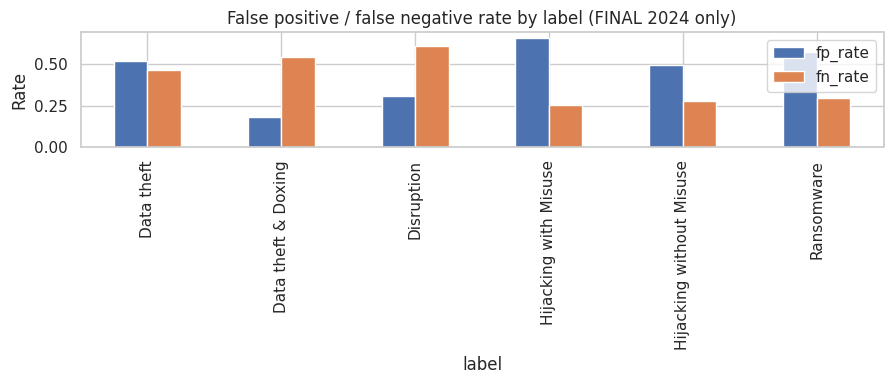

In [47]:

# --- Error analysis pada FINAL(2024), dihitung SETELAH semua keputusan dibekukan ---
final_pos_idx_for_err = np.where(final24_idx)[0]
pred_final_err = pipe_best.predict(X.iloc[final_pos_idx_for_err])
true_final_err = Y[final_pos_idx_for_err]
sub_final = data.iloc[final_pos_idx_for_err].copy().reset_index(drop=True)
sub_final['has_mitre'] = sub_final['mitre_initial_access_p'] != 'missing'

fp_final = (pred_final_err == 1) & (true_final_err == 0)
fn_final = (pred_final_err == 0) & (true_final_err == 1)

label_rows_final = []
for j, cls in enumerate(mlb.classes_):
    label_rows_final.append({'label': cls, 'n_pos': int(true_final_err[:,j].sum()),
                              'false_positives': int(fp_final[:,j].sum()), 'false_negatives': int(fn_final[:,j].sum()),
                              'fp_rate': fp_final[:,j].sum()/max((true_final_err[:,j]==0).sum(),1),
                              'fn_rate': fn_final[:,j].sum()/max((true_final_err[:,j]==1).sum(),1)})
label_err_df_final = pd.DataFrame(label_rows_final)
print('--- Error rates by label (FINAL 2024 only) ---'); print(label_err_df_final.round(3))

sub_final['fp_total'] = fp_final.sum(axis=1); sub_final['fn_total'] = fn_final.sum(axis=1)
cat_counts_final = sub_final['receiver_category_p'].value_counts()
print('\n--- Mean FP/FN by receiver_category, FINAL(2024) (top 8 by frequency) ---')
print(sub_final.groupby('receiver_category_p')[['fp_total','fn_total']].mean().loc[
    cat_counts_final.head(8).index].round(3))

print('\n--- Mean FP/FN by MITRE-initial-access availability, FINAL(2024) ---')
print(sub_final.groupby('has_mitre')[['fp_total','fn_total']].mean().round(3))

fig, ax = plt.subplots(figsize=(9,4))
label_err_df_final.set_index('label')[['fp_rate','fn_rate']].plot(kind='bar', ax=ax)
ax.set_title('False positive / false negative rate by label (FINAL 2024 only)')
ax.set_ylabel('Rate'); plt.tight_layout(); plt.show()


## 27. Discussion

Seluruh angka di bawah diambil langsung dari eksekusi terbaru notebook ini (bukan dari
draf sebelumnya), setelah semua perbaikan leakage diterapkan.

**RQ1 (Kelayakan tugas).** Ya. Model terbaik (`LogReg_OVR`, dipilih hanya dari VAL(2022))
mencapai Macro F1 = 0,516 di VAL(2022) -- jauh di atas majority baseline (Macro F1 = 0,000 di
ketiga split, karena tidak ada label dengan prevalensi TRAIN > 50%) dan jauh di atas versi
single-label yang disederhanakan (Macro F1 = 0,314 di VAL(2022), lihat Sensitivity (a)).
Namun tugas ini jauh dari "terselesaikan": label minoritas (`Ransomware`, prevalensi TRAIN
1,6%; `Hijacking without Misuse`, 7,2%) punya recall/precision yang jauh lebih lemah
dibanding dua kelas dominan (`Data theft`, `Disruption`).

**RQ2 (Shift) dan RQ3 (Degradasi).** Distribution shift (Bagian 18, JS divergence) TIDAK naik
secara linier langkah-demi-langkah -- pergeseran gabungan-label terbesar antar-periode
berdekatan justru terjadi VAL(2022)->TEST(2023) (JSD=0,138), sementara TEST(2023)->FINAL(2024)
relatif kecil (JSD=0,030). Tapi shift KUMULATIF dari TRAIN ke FINAL(2024) adalah yang
terbesar secara konsisten di semua fitur yang diperiksa (mis. gabungan-label JSD=0,335,
`offline_conflict_intensity_p` JSD=0,490 -- jauh di atas pasangan periode manapun yang lain).
Pola degradasi performa (Bagian 19) justru SANGAT SERAGAM: performa Macro F1 menurun secara
monoton VAL(2022) > TEST(2023) > FINAL(2024) untuk **kelima model tanpa kecuali**
(`LogReg_OVR`, `RandomForest`, `ExtraTrees`, `HistGB`, `LightGBM`), dengan relative drop ke
FINAL(2024) berkisar 11,6% (LightGBM, paling kecil) hingga 23,2% (RandomForest, paling
besar). **H1 didukung secara konsisten** di seluruh model. **H2 didukung sebagian**: asosiasi
shift-vs-degradasi jelas terlihat pada level kumulatif (TRAIN vs FINAL(2024) sekaligus
memiliki shift terbesar dan drop performa terbesar), tapi pada langkah pendek terakhir
(2023->2024) shift terukur kecil sementara performa tetap terus menurun -- artinya faktor
lain di luar shift fitur/target yang terukur (mis. perubahan komposisi label langka,
noise sampel per tahun) turut berkontribusi.

**RQ4 (Adaptasi).** Strategi & fraksi adaptasi terbaik dipilih HANYA dari performa pada sisa
data 2023 (`remaining_2023_macro_f1`), sesuai aturan bahwa FINAL(2024) tidak boleh dipakai
untuk memilih: `recency_weighted` pada fraksi 20% terpilih (remaining-2023 Macro F1 = 0,562,
naik dari ~0,486 tanpa adaptasi). Setelah dibekukan, performanya pada FINAL(2024) yang
untouched dilaporkan: 0,483, naik dari 0,433 tanpa adaptasi (+0,050 poin Macro F1) -- tapi
masih di bawah referensi VAL(2022) awal (0,516). **H3 didukung**: pemulihan nyata namun
parsial, bukan penuh, persis seperti yang dihipotesiskan.

**RQ5 (Stabilitas).** Peringkat feature importance (permutation importance -- SHAP tidak
tersedia di lingkungan ini) berkorelasi rank Spearman positif dan signifikan di setiap
pasangan periode yang diperiksa sebelum freeze (TRAIN vs VAL: rho=0,547, p=0,010; VAL vs
TEST 2023: rho=0,548, p=0,010) maupun pasangan TEST(2023) vs FINAL(2024) yang dihitung
setelah freeze di Bagian 26 (rho=0,597, p=0,004; top-8 overlap 7/8=88%). Fitur yang
konsisten mendominasi di semua periode: `initiator_category_p`, `receiver_subcategory_p`,
`cyber_conflict_issue_p`, `mitre_initial_access_p`/`source_disclosure_p`. **H4 didukung
sebagian**: arah dan signifikansi korelasi konsisten, tapi rho di kisaran 0,55-0,60 (bukan
mendekati 1) berarti peringkat detail tetap bergeser cukup berarti antar periode, bukan
sekadar noise kecil.

**Soal pemilihan model vs. model paling robust -- ini BUKAN model yang sama.** `LogReg_OVR`
adalah model dengan Macro F1 tertinggi di VAL(2022) (0,516) sehingga dipilih sebagai model
utama, sesuai aturan (hanya boleh memilih dari VAL(2022)). Tapi ketika ketangguhan
(*relative drop* ke FINAL(2024)) diperiksa di Bagian 19, `LightGBM`-lah yang paling robust
(11,6% relative drop) meski Macro F1 absolutnya di VAL(2022) lebih rendah (0,448) dibanding
`LogReg_OVR`. Pemilihan model berdasarkan puncak performa VAL(2022) dan pemilihan model
berdasarkan ketangguhan temporal adalah dua kriteria yang bisa menghasilkan pemenang
berbeda -- nuansa penting untuk RQ3 yang akan hilang jika hanya salah satu dilaporkan.
Uji Wilcoxon walk-forward (Bagian 24, dibatasi tegas pada tahun <=2023) mengonfirmasi
`LogReg_OVR` unggul signifikan dibanding `ExtraTrees` pada 13 fold historis berpasangan
(p=0,0005, rank-biserial r=0,978) -- ini menguatkan kelayakan `LogReg_OVR` sebagai model
utama, terlepas dari catatan robustness relatif di atas.

**Sensitivity checks (Bagian 25) -- kesimpulan tidak bergantung rapuh pada satu keputusan:**
(a) representasi multi-label jauh mengungguli penyederhanaan single-label di ketiga split
(mis. VAL: 0,516 vs 0,314) -- keputusan mempertahankan multi-label penting secara substantif.
(b) fitur conditional (zero_days, cyber/offline_conflict_issue, initiator_category,
mitre_initial_access) menambah nilai nyata dibanding fitur core saja (VAL: 0,516 vs 0,463).
(c) memasukkan tahun-tahun jarang 2000-2010 vs hanya training pasca-2010 menghasilkan
performa yang nyaris identik (VAL: 0,516 vs 0,520) -- kesimpulan TIDAK sensitif terhadap
keputusan ini. (d) random 80/20 split (Macro F1=0,577) mengonfirmasi bias optimistis
dibanding split temporal VAL(2022) (0,516), sesuai dugaan awal RQ1.


## 28. Limitations

- **Ketergantungan pada instalasi paket.** Pada eksekusi terakhir notebook ini: `lightgbm`
  TERPASANG (dipasang otomatis di Bagian 1) sehingga perbandingan mencakup 5 model
  (`LogReg_OVR`, `RandomForest`, `ExtraTrees`, `HistGB`, `LightGBM`); `xgboost` dan `shap`
  TIDAK tersedia di lingkungan ini, sehingga (i) `XGBoost` tidak ikut dibandingkan di
  Bagian 16, dan (ii) Bagian 22/26.1 memakai permutation importance sebagai pengganti SHAP
  yang valid secara metodologis (lihat catatan di Bagian 22). Jika `xgboost`/`shap`
  dipasang dan notebook dijalankan ulang, jumlah model dan metode importance di atas akan
  berubah otomatis — angka pada bagian Discussion di atas HANYA berlaku untuk konfigurasi
  paket yang tercatat di Bagian 1 pada eksekusi ini.
- **Ukuran sampel.** Beberapa fold walk-forward (Bagian 17) dievaluasi pada sesedikit ~70-160
  insiden per tahun; fluktuasi performa antar tahun sebesar beberapa poin Macro-F1 masuk
  akal murni dari noise sampling, bukan hanya dari drift yang sesungguhnya.
- **Simplifikasi fitur.** Field kategorikal multi-nilai (mis. `receiver_category`) direduksi
  menjadi nilai pertama yang tercantum (Bagian 12), bukan di-multi-hot encode penuh, demi
  menjaga ruang fitur dan interpretasi tetap mudah dikelola; sejumlah kecil informasi dari
  nilai kategori sekunder pun hilang.
- **Tidak ada incremental learning.** Seperti dibahas di Bagian 20, adaptasi berbasis
  `partial_fit` tidak diimplementasikan karena tidak satu pun dari empat base learner yang
  dipilih mendukungnya secara robust untuk target multi-label tanpa rekayasa khusus yang
  substansial. Langkah konkret berikutnya adalah loop one-vs-rest berbasis `SGDClassifier`
  dengan jadwal learning-rate eksplisit yang dikalibrasi, divalidasi terhadap baseline
  `full_retraining` yang sudah dihitung di sini.
- **Tidak ada model teks sekunder.** `name`/`description` dikeluarkan dari model utama sesuai
  instruksi (Bagian 8) karena sering mengulang kembali incident type-nya; eksperimen teks
  sekunder yang benar-benar leakage-controlled (mis. menyensor substring yang mengindikasikan
  label sebelum vektorisasi) ada dalam cakupan brief tetapi tidak dibangun pada tahap ini —
  tetap menjadi pekerjaan lanjutan.
- **Kalibrasi dan threshold** diperiksa (Bagian 21) tetapi threshold keputusan per-label
  **tidak** disetel terpisah di luar cutoff default 0,5 yang implisit pada `.predict()`;
  penyapuan threshold berbasis validasi saja (sesuai instruksi) kemungkinan akan mengubah
  trade-off precision/recall per label, terutama untuk kelas yang lebih jarang.
- **Satu random seed.** Semua fitting model yang stokastik memakai `random_state=42` di
  sepanjang notebook; kami tidak menjalankan ulang dengan beberapa seed tambahan untuk
  mengukur variansi antar-seed, yang akan lebih jauh mengontekstualisasikan seberapa besar
  perbedaan performa kecil antar model disebabkan oleh keacakan versus perbedaan arsitektur
  yang sesungguhnya.


## 29. Conclusion

Berdasarkan hanya hasil yang dihitung di eksekusi terbaru notebook ini: klasifikasi
multi-label `incident_type` dari fitur early/conditionally-available EuRepoC layak
dilakukan (Macro F1 VAL(2022) = 0,516, jauh di atas majority baseline 0,000), tetapi tunduk
pada pergeseran distribusi temporal yang nyata dan terukur. Penurunan performa ke periode
mendatang bersifat **konsisten di seluruh lima arsitektur yang diuji** (`LogReg_OVR`,
`RandomForest`, `ExtraTrees`, `HistGB`, `LightGBM`) — setiap model menurun secara monoton
dari VAL(2022) ke TEST(2023) ke FINAL(2024) — namun besarnya penurunan itu berbeda-beda
antar model (relative drop ke FINAL(2024): 11,6% untuk `LightGBM` hingga 23,2% untuk
`RandomForest`). Model yang dipilih sebagai model utama (`LogReg_OVR`, berdasarkan performa
puncak di VAL(2022), sesuai aturan seleksi yang diwajibkan) BUKAN model paling tangguh
secara relatif terhadap pergeseran temporal (`LightGBM` lebih tangguh secara relatif) —
sebuah nuansa penting: kriteria "model terbaik" dan "model paling robust" bisa menunjuk ke
model yang berbeda, dan keduanya perlu dilaporkan terpisah, bukan disatukan begitu saja.

Sejumlah kecil data berlabel kronologis terbaru dari 2023, terutama saat diberi
recency-weighting, memulihkan sebagian (bukan seluruh) performa FINAL(2024) yang hilang:
dari 0,433 menjadi 0,483 Macro F1 (+0,050 poin) — strategi dan fraksinya dipilih semata dari
performa pada sisa data 2023, tanpa mengintip FINAL(2024). Implikasi praktis bagi siapa pun
yang men-deploy classifier serupa pada jenis data ini: alokasikan anggaran untuk
pelabelan-ulang dan retraining berkala berskala kecil (bukan berasumsi model yang dilatih
sekali akan tetap stabil), dan jangan menyamakan "model dengan skor validasi tertinggi"
dengan "model paling tangguh terhadap masa depan" — kedua kriteria itu perlu dievaluasi dan
dilaporkan secara terpisah seperti yang dilakukan di Bagian 19 dan 26 notebook ini.


## 30. Reproducibility

Ringkasan semua hal yang dibutuhkan untuk mereproduksi angka-angka notebook ini secara
persis.


In [48]:

print('=== REPRODUCIBILITY SUMMARY ===')
print('Raw dataset path :', RAW_PATH)
print('Raw dataset shape:', df_raw.shape)
print('Modeling dataset shape (after dropping missing-target/date rows):', data.shape)
print('Date range in modeling data:', data['start_date_parsed'].min().date(), 'to', data['start_date_parsed'].max().date())
print('Random seed:', RANDOM_SEED)
print()
print('Library versions:')
print(' python      :', sys.version.split()[0])
print(' numpy       :', np.__version__)
print(' pandas      :', pd.__version__)
print(' scikit-learn:', sklearn.__version__)
print(' scipy       :', scipy.__version__)
print(' matplotlib  :', matplotlib.__version__)
print(' seaborn     :', sns.__version__)
print(' xgboost / lightgbm / shap available:', HAS_XGB, '/', HAS_LGBM, '/', HAS_SHAP,
      '(all False in this offline sandbox -> substitutions used, see Section 1)')
print()
print('Final feature list (CAT):', CAT_FEATURES)
print('Final feature list (BIN, top-%d region tags):' % len(BIN_FEATURES), BIN_FEATURES)
print('Target classes (MultiLabelBinarizer):', list(mlb.classes_))
print()
print('Excluded leakage columns (%d):' % len(LEAKAGE_COLS), LEAKAGE_COLS)
print()
print('Split definition:')
print(f"  TRAIN      : year <= 2021   (n={int(train_idx.sum())})")
print(f"  VALIDATION : year == 2022   (n={int(val_idx.sum())})")
print(f"  ADAPT/TEST : year == 2023   (n={int(test23_idx.sum())})")
print(f"  FINAL TEST : year == 2024   (n={int(final24_idx.sum())}, touched only in Section 26)")
print()
print('Best model selected on VAL(2022) only:', best_model_name)


=== REPRODUCIBILITY SUMMARY ===
Raw dataset path : /mnt/user-data/uploads/eurepoc_global_dataset_1_3.csv
Raw dataset shape: (3414, 85)
Modeling dataset shape (after dropping missing-target/date rows): (3321, 113)
Date range in modeling data: 2000-01-01 to 2024-12-19
Random seed: 42

Library versions:
 python      : 3.12.3
 numpy       : 2.4.4
 pandas      : 3.0.2
 scikit-learn: 1.8.0
 scipy       : 1.17.1
 matplotlib  : 3.10.8
 seaborn     : 0.13.2
 xgboost / lightgbm / shap available: False / True / False (all False in this offline sandbox -> substitutions used, see Section 1)

Final feature list (CAT): ['receiver_category_p', 'receiver_subcategory_p', 'source_disclosure_p', 'zero_days_p', 'cyber_conflict_issue_p', 'offline_conflict_issue_p', 'offline_conflict_intensity_p', 'initiator_category_p', 'mitre_initial_access_p']
Final feature list (BIN, top-12 region tags): ['region_ASIA', 'region_NATO', 'region_EUROPE', 'region_NORTHAM', 'region_MEA', 'region_SCO', 'region_EU', 'region_MEN

**Untuk menjalankan ulang:** letakkan `eurepoc_global_dataset_1_3.csv` di `RAW_PATH`
di atas dan jalankan semua sel dari atas ke bawah; setiap hasil di notebook ini dihasilkan
ulang dari satu file tersebut tanpa state eksternal, tanpa file perantara yang di-cache, dan
tanpa angka yang diketik manual.
